# 04 — Forecasting con ARIMA y SARIMA
 vamos a predecir las ventas diarias de **una sola serie** con modelos estadísticos clásicos (ARIMA y SARIMA).

**¿Qué es una serie de tiempo?** Una lista de mediciones de la misma cosa, tomadas en orden y a intervalos regulares. Acá: las unidades vendidas de un producto en una tienda, **un dato por día**.

La diferencia con un dataset "normal" (tabular) es clave:
- En un dataset tabular, cada fila es independiente: el orden de las filas no importa y se pueden mezclar.
- En una serie de tiempo, **el orden ES la información**. Lo que se vendió ayer ayuda a predecir lo que se vende hoy. Por eso nunca se mezclan las filas ni se parte al azar (ver DEC-002).

**Plan del notebook** (un paso por sección):
0. Preparación y **reglas de medición** (métrica, horizonte, backtesting), fijadas antes de modelar. ✔
1. Elegir una serie, graficarla y medir el error de las **líneas base**. ✔
2. Descomponerla en tendencia, estacionalidad y ruido, y tratar el 25 de diciembre. ✔
3. Estacionariedad.
   - A. Diagnóstico: gráficos y tests ADF/KPSS. ✔
   - B. Diferenciar (simple y estacional) y elegir `d` y `D`. ✔
4. Leer los gráficos ACF/PACF para elegir los órdenes del modelo.
   - A. Retardos cortos: ACF y PACF de los primeros días para elegir `p` y `q`. ✔
   - B. Retardos estacionales (7, 14, 21...) para elegir `P` y `Q` y armar la grilla de candidatos. ✔
5. Ajustar un SARIMA, elegir órdenes y `K` con **backtesting dentro de `train`** y compararlo con las líneas base. Medir **una sola vez** en `valid`.
   - A. Ajustar los 6 candidatos de la grilla sobre toda la serie y revisar que converjan. ✔
   - B. Backtesting de los candidatos (y `K` de Fourier) contra las líneas base, y elegir uno. ✔
   - C. Residuos del elegido y medición única en `valid`. ✔
   - D. Backtesting ampliado a noviembre-diciembre, para entender el resultado en `valid`. ✔
6. Compararlo con el modelo de boosting de la solución del curso.

Los fundamentos de cada paso están explicados en [`01_Documentos/fundamentos_series_tiempo.md`](../01_Documentos/fundamentos_series_tiempo.md).

**Reglas del notebook**
- Se explora y se entrena **solo con `train`**. Los órdenes se eligen con backtesting dentro de `train`; `valid` se usa **una sola vez**, al final del paso 5, con el modelo ya elegido. `reserva` no se toca.
- Las observaciones se escriben **después de ver los números**.
- Las decisiones con alternativa descartada están en `decisions.md` (resumen) y `decisions_detalle.md` (detalle).

---

### Conclusiones hasta ahora
| # | Qué encontramos | Dónde |
|---|---|---|
| 1 | La serie `CA_3` / `FOODS_3_586` está **completa** (1.044 días) y es de las 8 sin alertas del notebook 03. | [1.1](#sec-1-1) |
| 2 | Tiene un **ciclo semanal fuerte** (domingo y sábado ~40 % sobre el miércoles), una **ola anual suave** y **ninguna tendencia**. | [1.5](#sec-1-5) |
| 3 | La vara a superar: la mejor línea base comete un error medio de **13,7 unidades por día** (18,6 % de la media). | [1.6](#sec-1-6) |
| 4 | La estacionalidad se suma (modelo **aditivo**) y la ola anual se modela con **Fourier**, no día por día. | [2](#sec-2) |
| 5 | Los dos **25 de diciembre** (tienda cerrada) se reemplazan por el mismo día de la semana anterior antes de modelar. | [2.5](#sec-2-5) |
| 6 | La serie **no tiene tendencia ni deriva** (`d = 0` de partida); lo que no es estacionario es el ciclo semanal. | [3](#sec-3) |
| 7 | **No hace falta diferenciar** (`d = 0`, `D = 0`): el ciclo semanal es fijo y se modela con términos estacionales; `D = 1` deja huella de sobrediferenciación. | [3B](#sec-3b) |
| 8 | En los retardos cortos la serie se lee como un **AR(1)** (`p = 1` y `q = 0` de partida): la PACF se corta después del retardo 1 y la ACF decae. | [4A](#sec-4a) |
| 9 | En los múltiplos de 7 la PACF pide `P = 1` (0,24, 0,16 y 0,17 en los retardos 7, 14 y 21) y la ACF no decae (ciclo fijo). SARIMA de partida: **(1, 0, 0)(1, 0, 0)₇**, más una lista corta de 6 candidatos para el paso 5. | [4B](#sec-4b) |
| 10 | Los 6 candidatos **convergen**. El de partida da `φ` = 0,36 y `Φ` = 0,32; con `Q = 1` el AR estacional sube a 0,98 y el MA estacional queda en −0,88 (casi se cancelan), y el ajuste mejora (AIC 8.480 contra 8.645). | [5A](#sec-5a) |
| 11 | En el backtesting a 28 días, **SARIMAX (1, 0, 0)(1, 0, 1)₇ con Fourier `K` = 1** comete un MAE de 11,7 contra 13,7 de la línea base y le gana en los 6 cortes. Sin Fourier la mejora es mínima (13,3 y 13,4). | [5B](#sec-5b) |
| 12 | En `valid` (medición única), el SARIMAX elegido **no le gana a la línea base**: MAE 10,4 contra 9,2 de la media de 4 semanas, al revés de lo que mostró el backtesting. El coeficiente estacional quedó en 0,9997 (el modelo se comporta como `D = 1`). | [5C](#sec-5c) |
| 13 | Con noviembre-diciembre de 2013 y 2014 en el backtesting, el SARIMAX sigue ganándole a la media de 4 semanas pero por poco (MAE 12,3 contra 13,2), y Fourier no mejora en esas semanas. La ventaja es chica y no consistente (en `valid` pierde). | [5D](#sec-5d) |

<a id="sec-0"></a>

## 0. Preparación
Mismas convenciones que el notebook 03: rutas con `Path` y nombres de columnas en constantes, así las funciones no tienen valores fijos adentro (DEC-005).

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from statsmodels.tsa.seasonal import seasonal_decompose, STL, MSTL
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf
from statsmodels.tools.sm_exceptions import InterpolationWarning

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)

DATOS = (Path("..") / "02_datos").resolve()
RUTA_TRAIN = DATOS / "03_Entrenamiento" / "train.parquet"

CLAVE_SERIE = ["store_id", "item_id"]   # una serie = una tienda + un producto
COL_FECHA = "date"
COL_VENTAS = "ventas"

# Serie elegida para aprender (ver sección 1.1 y DEC-006)
SERIE = {"store_id": "CA_3", "item_id": "FOODS_3_586"}


def cargar_tablon(ruta):
    """Lee un parquet (trae `date` como índice) y devuelve `date` como columna."""
    return pd.read_parquet(ruta).reset_index()


train = cargar_tablon(RUTA_TRAIN)
print(train.shape)
print(train[COL_FECHA].min(), "->", train[COL_FECHA].max())

(20809, 19)
2013-01-01 00:00:00 -> 2015-11-10 00:00:00


<a id="sec-0-1"></a>

### 0.1 Cómo vamos a medir (se fija **antes** de modelar)
Si la forma de medir se elige después de ver los resultados, es fácil terminar eligiendo la que más favorece al modelo. Por eso la dejamos fija desde ahora (DEC-011):

- **Horizonte: 28 días.** Es lo que mide `valid` (4 semanas completas, DEC-002).
- **Métrica: MAE** (*error absoluto medio*): en promedio, por cuántas unidades por día se equivoca el pronóstico. Se lee en las mismas unidades que las ventas. Para tener una idea del tamaño, también la expresamos como % de la media de la serie.
- **Métrica secundaria: RMSE** (raíz del error cuadrático medio). Está en las mismas unidades, pero eleva cada error al cuadrado antes de promediar, así que pesa más los errores grandes. **No decide** qué modelo gana (eso lo hace el MAE, fijado antes de modelar): se mira el cociente RMSE/MAE como diagnóstico. Cerca de 1 son errores parejos; bastante más de 1 indica pocos errores muy grandes escondidos en el promedio.
- **Líneas base:** reglas simples que cualquier modelo tiene que superar. Si SARIMA no le gana a "repetir la semana pasada", su complejidad no aporta nada.
  - **Naive estacional:** cada día se pronostica igual al mismo día de la última semana conocida (`y[t-7]`).
  - **Media de 4 semanas:** cada día de la semana se pronostica con el promedio de los últimos 4 iguales (los últimos 4 lunes, etc.).
- **Backtesting (*rolling origin*):** en vez de una sola prueba, simulamos varias veces "estar en el pasado". Se entrena hasta una fecha, se pronostican los 28 días siguientes y se compara con lo que pasó; después se corre la fecha 28 días y se repite. Usamos **6 cortes**, todos dentro de `train`. Así los órdenes del modelo se eligen con 6 pruebas y no con `valid`, que queda limpio para el final.

In [2]:
HORIZONTE = 28   # días a pronosticar (igual que valid)
N_CORTES = 6     # cantidad de pruebas del backtesting


def mae(real, pronostico):
    """Error absoluto medio: unidades por día que se equivoca el pronóstico."""
    return float(np.mean(np.abs(np.asarray(real) - np.asarray(pronostico))))


def rmse(real, pronostico):
    """Raíz del error cuadrático medio: como el MAE, pero pesa más los errores grandes. Es secundaria."""
    return float(np.sqrt(np.mean((np.asarray(real) - np.asarray(pronostico)) ** 2)))


def cortes_backtest(y, horizonte=HORIZONTE, n_cortes=N_CORTES):
    """Pares (historia, futuro) de rolling origin. El último futuro termina en el último día de y."""
    cortes = []
    for k in range(n_cortes, 0, -1):
        fin_historia = len(y) - k * horizonte
        cortes.append((y.iloc[:fin_historia], y.iloc[fin_historia:fin_historia + horizonte]))
    return cortes


def naive_estacional(historia, horizonte, periodo=7):
    """Repite la última semana conocida."""
    ultima = historia.iloc[-periodo:].to_numpy()
    return np.resize(ultima, horizonte)


def media_ultimas_semanas(historia, horizonte, semanas=4, periodo=7):
    """Cada día de la semana = promedio de sus últimas `semanas` apariciones."""
    tramo = historia.iloc[-semanas * periodo:].to_numpy().reshape(semanas, periodo)
    return np.resize(tramo.mean(axis=0), horizonte)


def backtest(y, metodo, horizonte=HORIZONTE, n_cortes=N_CORTES):
    """MAE (principal) y RMSE (secundaria) de un método en cada corte. `metodo(historia, horizonte)` devuelve un array."""
    filas = []
    for historia, futuro in cortes_backtest(y, horizonte, n_cortes):
        pronostico = metodo(historia, horizonte)
        filas.append({"desde": futuro.index[0].date(), "hasta": futuro.index[-1].date(),
                      "mae": mae(futuro, pronostico), "rmse": rmse(futuro, pronostico)})
    return pd.DataFrame(filas)

<a id="sec-1-1"></a>

## 1. Elegir una serie y graficarla

### 1.1 ¿Por qué una sola serie?
ARIMA y SARIMA son modelos **univariados**: aprenden de la historia de **una** serie y de nada más. Si tenemos 20 series, en la práctica se ajustan 20 modelos, uno por serie.

Para aprender conviene empezar con una sola, y que sea **"fácil"**:
- **Pocos ceros.** SARIMA supone que la serie se mueve alrededor de un nivel de forma más o menos continua. Una serie con muchos días en cero (demanda *intermitente*) necesita otros métodos (por ejemplo Croston), y confundiría el aprendizaje.
- **Volumen alto.** Con ventas de 2 o 3 unidades por día, el ruido tapa cualquier patrón.
- **Poca variación relativa.** Lo medimos con el **coeficiente de variación** (CV = desvío estándar / media). Un CV bajo indica una serie más estable y predecible.

El notebook 03 ya hizo el filtro grueso: su [ficha por serie](03_Calidad_Datos_EDA.ipynb#sec-4) marcó **8 series sin ninguna alerta** (sin rachas largas de ceros, sin semanas hundidas, sin saltos anuales). Para comparar también el volumen y el CV, que la ficha no tiene, calculamos las tres cosas de arriba para las 20 series:

In [3]:
def resumen_series(df, clave=CLAVE_SERIE, col_valor=COL_VENTAS):
    """Una fila por serie: cantidad de días, media, % de días en cero y coeficiente de variación."""
    g = df.groupby(clave)[col_valor]
    resumen = pd.DataFrame({
        "dias": g.size(),
        "media": g.mean(),
        "pct_ceros": g.apply(lambda s: (s == 0).mean() * 100),
        "cv": g.std() / g.mean(),   # cuanto más bajo, más estable
    })
    return resumen.round(2).sort_values(["pct_ceros", "cv"])


resumen_series(train)

dias   media  pct_ceros    cv
store_id item_id                                   
CA_3     FOODS_3_586  1044   73.79       0.19  0.24
         FOODS_3_555  1044   32.61       0.19  0.31
         FOODS_3_252  1044   45.94       0.29  0.37
         FOODS_3_714  1044   28.96       0.48  0.40
CA_4     FOODS_3_252  1044   13.21       0.48  0.53
         FOODS_3_586  1044   17.95       0.57  0.37
         FOODS_3_714  1044   11.23       0.86  0.53
         FOODS_3_555  1044    7.40       2.39  0.52
CA_3     FOODS_3_288  1012   33.80       7.41  0.58
         FOODS_3_202  1044   23.14       9.29  0.63
         FOODS_3_090  1044  127.25       9.58  0.76
         FOODS_3_587  1044   23.45      10.34  0.88
         FOODS_3_120  1044   54.26      18.39  0.76
CA_4     FOODS_3_090  1044   27.90      19.44  0.74
         FOODS_3_202  1044    9.37      20.40  0.70
         FOODS_3_288  1005    4.10      21.79  0.91
CA_3     FOODS_3_329  1044   19.84      31.70  0.89
CA_4     FOODS_3_329  1044    4.39      39.56  1.14
         FOODS_3_587  1044    9.21      41.86  0.99
         FOODS_3_120  1044   10.94      45.31  1.30

> **Conclusión:** elegimos **`CA_3` / `FOODS_3_586`** (DEC-006): es la candidata más limpia para aprender.

**Evidencia:** está entre las 8 series sin alertas del notebook 03, empata en el primer lugar con menos ceros (0,19 %, apenas 2 días), es la de menor CV (0,24) y la segunda de mayor volumen (73,8 unidades por día de media).

**Qué hacemos:** seguimos con esta serie. Las series con 30-45 % de ceros quedan para más adelante.

### 1.2 De tabla a serie de tiempo
Para `statsmodels` (la librería de ARIMA/SARIMA) una serie de tiempo es una `pd.Series` cuyo **índice son fechas** con una **frecuencia declarada**. En pandas:
- `DatetimeIndex`: un índice de fechas. Permite hacer cosas como `y["2014-07"]` (todo julio de 2014) o `y.resample("MS")` (agrupar por mes).
- **Frecuencia** (`freq`): le dice a pandas cada cuánto hay un dato. `"D"` = diaria. Con `.asfreq("D")` se fuerza un dato por día: si faltara una fecha, aparece como `NaN` en vez de quedar un salto escondido.

¿Por qué importa no tener huecos? Porque los modelos de series asumen que el dato *t-1* es **el día anterior**. Si faltara un día, "ayer" en realidad sería "anteayer" y el modelo aprendería mal la memoria de la serie.

In [4]:
def extraer_serie(df, filtro, col_fecha=COL_FECHA, col_valor=COL_VENTAS, freq="D"):
    """Devuelve una pd.Series con índice de fechas y frecuencia fija para una serie del tablón.

    filtro: dict {columna: valor} que identifica la serie, por ejemplo SERIE.
    Falla si hay fechas repetidas o huecos, en vez de dejar un problema silencioso.
    """
    mascara = pd.Series(True, index=df.index)
    for col, valor in filtro.items():
        mascara &= df[col] == valor
    serie = df.loc[mascara].set_index(col_fecha)[col_valor].sort_index()

    if not serie.index.is_unique:
        raise ValueError("Hay fechas repetidas: la serie no está bien identificada")
    serie = serie.asfreq(freq)  # un dato por período; los huecos aparecerían como NaN
    huecos = serie.isna().sum()
    if huecos:
        raise ValueError(f"La serie tiene {huecos} períodos sin dato")
    serie.name = "/".join(filtro.values())
    return serie


y = extraer_serie(train, SERIE)
print(y.index.freq, "|", len(y), "días |", y.index.min().date(), "->", y.index.max().date())
y.describe().round(1)

<Day> | 1044 días | 2013-01-01 -> 2015-11-10


count    1044.0
mean       73.8
std        18.0
min         0.0
25%        61.0
50%        73.0
75%        85.0
max       142.0
Name: CA_3/FOODS_3_586, dtype: float64

### 1.3 La serie completa
Lo primero que se hace con **cualquier** serie es graficarla entera. Antes de modelar, a ojo, buscamos tres cosas:
- **Tendencia:** ¿el nivel sube o baja a lo largo de los años?
- **Estacionalidad:** ¿hay un patrón que se repite cada cierto período fijo (semana, año)?
- **Cosas raras:** picos, caídas a cero, cambios bruscos de nivel.

La serie diaria es muy "nerviosa". Para ver el movimiento de fondo le superponemos **medias móviles**: el promedio de los últimos *n* días, recalculado cada día. La de 7 días borra el patrón semanal (cada ventana tiene exactamente un lunes, un martes...). La de 28 días suaviza todavía más y deja ver la forma a lo largo del año.

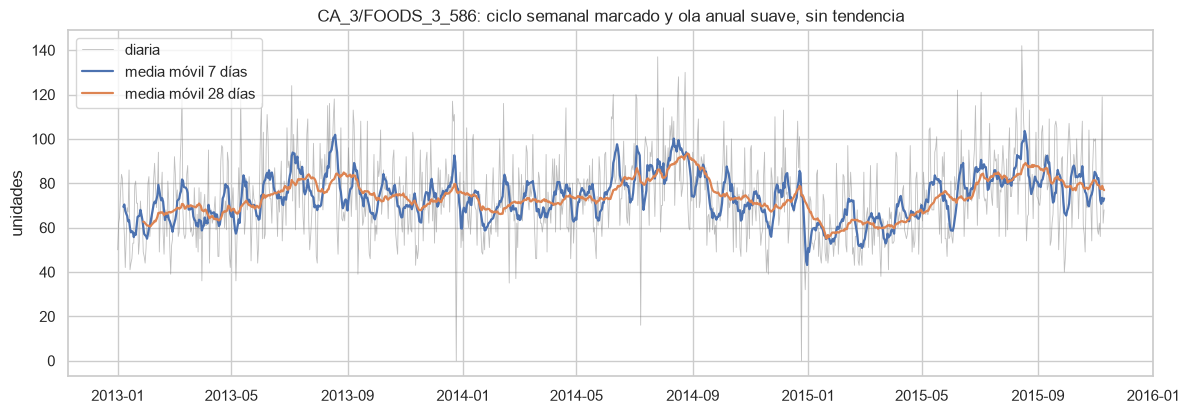

In [5]:
def graficar_serie(y, ventanas=(7, 28), titulo=None):
    """Serie diaria con sus medias móviles superpuestas."""
    fig, ax = plt.subplots(figsize=(14, 4.5))
    ax.plot(y.index, y, lw=0.6, alpha=0.5, color="grey", label="diaria")
    for n in ventanas:
        # rolling(n).mean(): promedio de los últimos n días (incluido el actual)
        ax.plot(y.index, y.rolling(n).mean(), lw=1.6, label=f"media móvil {n} días")
    ax.set_title(titulo or f"Ventas diarias — {y.name}")
    ax.set_ylabel("unidades")
    ax.legend(loc="upper left")
    plt.show()


graficar_serie(y, titulo=f"{y.name}: ciclo semanal marcado y ola anual suave, sin tendencia")

### 1.4 Zoom: las últimas 8 semanas
Con casi 3 años en pantalla no se ve el detalle de cada semana. Hacemos zoom sobre las últimas 8 semanas y marcamos los fines de semana para ver si el patrón semanal es visible a ojo.

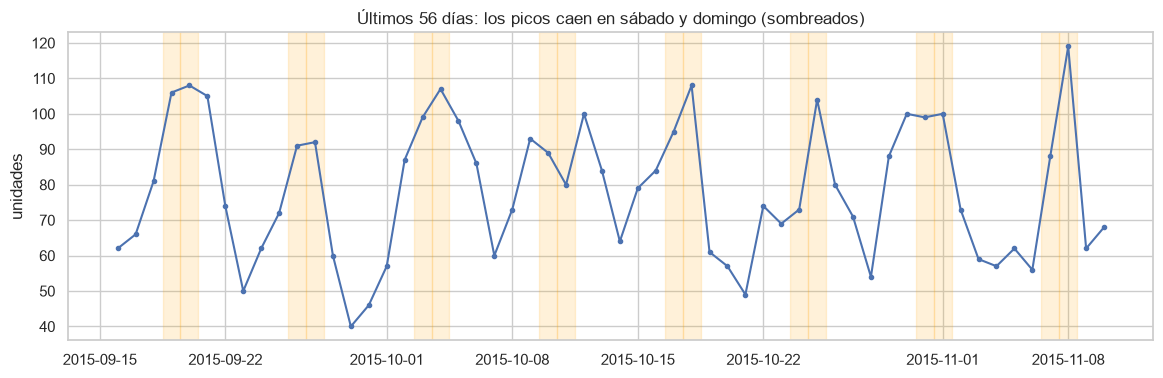

In [6]:
def graficar_zoom(y, dias=56):
    """Últimos `dias` de la serie, con sábados y domingos sombreados."""
    tramo = y.iloc[-dias:]
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(tramo.index, tramo, marker="o", ms=3)
    for fecha in tramo.index[tramo.index.day_of_week >= 5]:   # 5 = sábado, 6 = domingo
        ax.axvspan(fecha - pd.Timedelta(hours=12), fecha + pd.Timedelta(hours=12), color="orange", alpha=0.15)
    ax.set_title(f"Últimos {dias} días: los picos caen en sábado y domingo (sombreados)")
    ax.set_ylabel("unidades")
    plt.show()


graficar_zoom(y)

<a id="sec-1-5"></a>

### 1.5 Confirmar con números lo que se ve
 Promediamos las ventas por día de la semana (patrón semanal), por mes (patrón anual) y por año (tendencia).

*Nota:* acá usamos `day_of_week` de pandas (0 = lunes ... 6 = domingo), no la columna `wday` del tablón, que sigue la convención M5 (1 = sábado).

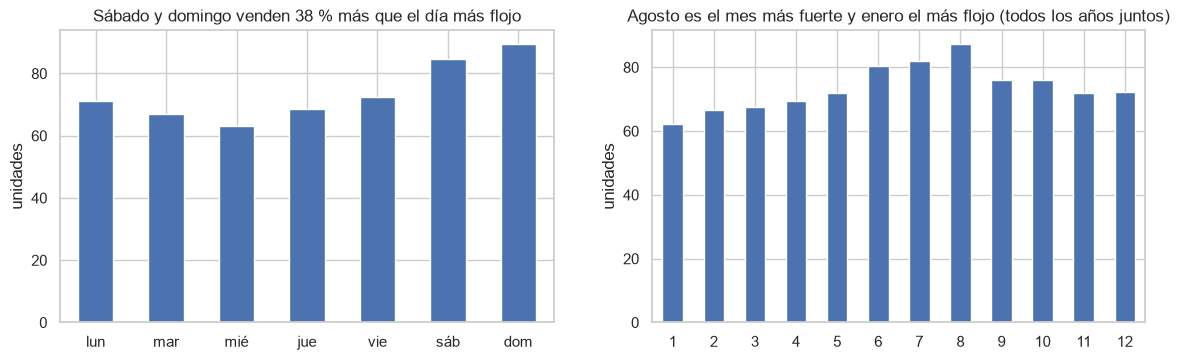

Media por año: {2013: 72.8, 2014: 75.3, 2015: 73.2}
Días con 0 ventas: [datetime.date(2013, 12, 25), datetime.date(2014, 12, 25)]
5 días con más ventas:
date
2015-08-15    142
2014-07-26    137
2014-08-24    130
2014-08-17    128
2013-07-04    124
Name: CA_3/FOODS_3_586, dtype: int64


In [7]:
DIAS = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]

por_dia = y.groupby(y.index.day_of_week).mean().rename(index=dict(enumerate(DIAS)))
por_mes = y.groupby(y.index.month).mean()
por_anio = y.groupby(y.index.year).mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
MESES = dict(enumerate(["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto",
                        "septiembre", "octubre", "noviembre", "diciembre"], start=1))
pct_finde = 100 * (por_dia[["sáb", "dom"]].mean() / por_dia.min() - 1)
por_dia.plot.bar(ax=axes[0], rot=0, title=f"Sábado y domingo venden {pct_finde:.0f} % más que el día más flojo")
por_mes.plot.bar(ax=axes[1], rot=0, title=f"{MESES[por_mes.idxmax()].capitalize()} es el mes más fuerte y {MESES[por_mes.idxmin()]} el más flojo (todos los años juntos)")
for ax in axes:
    ax.set_ylabel("unidades"); ax.set_xlabel("")
plt.show()

print("Media por año:", por_anio.round(1).to_dict())
print("Días con 0 ventas:", [d.date() for d in y.index[y == 0]])
print("5 días con más ventas:")
print(y.nlargest(5))

> **Conclusión:** la serie tiene **nivel estable, un ciclo semanal muy marcado y un ciclo anual suave**. No tiene tendencia.

**Evidencia:**
- La serie está **completa**: 1.044 días seguidos (2013-01-01 a 2015-11-10), sin fechas repetidas ni huecos.
- **Patrón semanal fuerte:** el domingo (89,5 de media) y el sábado (84,7) venden bastante más que el miércoles, el día más flojo (63,2). Es una diferencia de alrededor del 40 %. En el zoom se ve: los picos caen en los fines de semana. Esto es **estacionalidad con período 7**, el `s = 7` que va a usar SARIMA.
- **Patrón anual:** la media móvil de 28 días sube en verano y cae a principios de cada año. Juntando los tres años, agosto es el mes más fuerte (87,4 de media) y enero el más flojo (62,3); mes a mes, el máximo es agosto de 2014 (90,9) y el mínimo enero de 2015 (58,5). Varios de los días récord son de verano (142 el 2015-08-15, 137 el 2014-07-26). Esto es **estacionalidad anual (período 365)**, que SARIMA no maneja bien con datos diarios.
- **Sin tendencia clara:** la media por año casi no cambia (72,8 en 2013, 75,3 en 2014 y 73,2 en 2015, este último sin noviembre y diciembre).
- **Solo 2 ceros**, los dos un 25 de diciembre (2013 y 2014), cuando las tiendas cierran. No son demanda cero, son tienda cerrada.

**Qué hacemos:** medir el error de las líneas base (1.6), separar los componentes en el paso 2 y tratar los dos 25 de diciembre en [2.5](#sec-2-5).

<a id="sec-1-6"></a>

### 1.6 Líneas base: ¿cuánto se equivoca una regla simple?
Antes de construir cualquier modelo, medimos con el backtesting de 0.1 cuánto se equivocan las dos reglas simples. Ese error es **la vara que SARIMA tiene que superar** en el paso 5.

Los 6 cortes cubren las últimas 24 semanas de `train` (de fines de mayo a noviembre de 2015), así que ninguno incluye un 25 de diciembre.

                             desde       hasta   mae  rmse
metodo           corte                                    
naive estacional 0      2015-05-27  2015-06-23  16.3  20.8
                 1      2015-06-24  2015-07-21  12.4  17.4
                 2      2015-07-22  2015-08-18  15.4  20.3
                 3      2015-08-19  2015-09-15  24.6  31.0
                 4      2015-09-16  2015-10-13  23.4  27.6
                 5      2015-10-14  2015-11-10  17.2  20.9
media 4 semanas  0      2015-05-27  2015-06-23  13.6  17.5
                 1      2015-06-24  2015-07-21  15.0  18.5
                 2      2015-07-22  2015-08-18  14.1  18.9
                 3      2015-08-19  2015-09-15  13.2  17.3
                 4      2015-09-16  2015-10-13  15.1  18.3
                 5      2015-10-14  2015-11-10  11.5  14.6


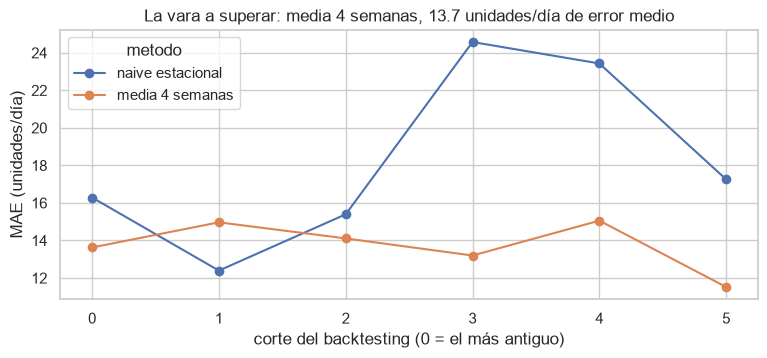

,mae_medio,mae_min,mae_max,mae_%_de_la_media,rmse_medio,rmse/mae
metodo,,,,,,
media 4 semanas,13.7,11.5,15.1,18.6,17.5,1.3
naive estacional,18.2,12.4,24.6,24.7,23.0,1.3


In [8]:
lineas_base = {"naive estacional": naive_estacional, "media 4 semanas": media_ultimas_semanas}
por_corte = pd.concat({nombre: backtest(y, metodo) for nombre, metodo in lineas_base.items()}, names=["metodo", "corte"])
print(por_corte.round(1).to_string())

resumen_base = por_corte.groupby("metodo")["mae"].agg(mae_medio="mean", mae_min="min", mae_max="max")
resumen_base["mae_%_de_la_media"] = 100 * resumen_base["mae_medio"] / y.mean()
resumen_base["rmse_medio"] = por_corte.groupby("metodo")["rmse"].mean()
resumen_base["rmse/mae"] = resumen_base["rmse_medio"] / resumen_base["mae_medio"]

ax = por_corte["mae"].unstack("metodo").plot(marker="o", figsize=(9, 3.5))
mejor = resumen_base["mae_medio"].idxmin()
ax.set_title(f"La vara a superar: {mejor}, {resumen_base.loc[mejor, 'mae_medio']:.1f} unidades/día de error medio")
ax.set_xlabel("corte del backtesting (0 = el más antiguo)"); ax.set_ylabel("MAE (unidades/día)")
plt.show()
resumen_base.round(1)

> **Conclusión:** la vara a superar es la **media de 4 semanas**: se equivoca en promedio **13,7 unidades por día** (18,6 % de la media de la serie). SARIMA tiene que bajar de ahí.

**Evidencia:**
- **Media de 4 semanas:** MAE medio 13,7, entre 11,5 y 15,1 según el corte.
- **Naive estacional:** MAE medio 18,2, entre 12,4 y 24,6. Es peor y más inestable: copiar una sola semana arrastra todo su ruido, y promediar 4 lo suaviza.
- La naive estacional gana en un solo corte (24-jun a 21-jul de 2015: 12,4 contra 15,0).

**Qué hacemos:** en el paso 5, comparar SARIMA contra la media de 4 semanas con **los mismos 6 cortes**.

<a id="sec-2"></a>

## 2. Descomponer la serie: tendencia, estacionalidad y ruido

### 2.1 La idea
**Descomponer** una serie es separarla en piezas más simples que, sumadas, la reconstruyen:

| Componente | Qué es | En esta serie |
|---|---|---|
| **Tendencia** (*trend*) | El nivel de fondo, que cambia despacio | Casi plana (sección 1) |
| **Estacionalidad** (*seasonal*) | Un patrón que se repite cada período fijo | Semanal (7 días) y anual (365) |
| **Residuo** (*resid*) | Lo que sobra: ruido, eventos, sorpresas | Picos sueltos, 25 de diciembre |

¿Para qué sirve? Para **medir** cuánto pesa cada pieza y decidir qué tiene que modelar SARIMA. Un SARIMA bien elegido captura la tendencia y la estacionalidad; si después de modelar el residuo todavía muestra un patrón, el modelo se quedó corto.

Las piezas se pueden combinar de dos maneras:
- **Aditiva:** `y = tendencia + estacionalidad + residuo`. El efecto del domingo es "+X unidades", siempre las mismas.
- **Multiplicativa:** `y = tendencia × estacionalidad × residuo`. El efecto del domingo es "+X %": si el nivel sube, el pico del domingo crece con él.

¿Cómo saber cuál usar? Mirando si **la amplitud del ciclo semanal crece cuando sube el nivel**. Para cada mes calculamos el nivel (la media) y la amplitud (el día de la semana más alto menos el más bajo).

Correlación nivel-amplitud: 0.11


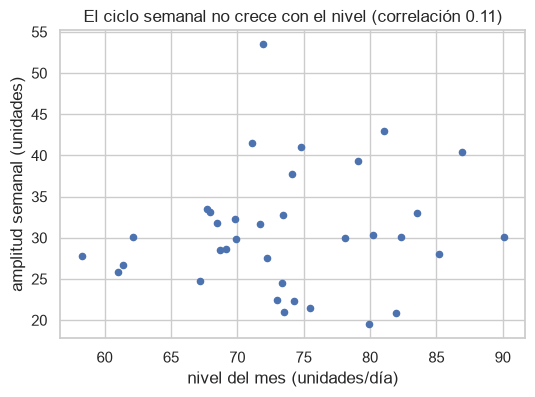

In [9]:
def amplitud_vs_nivel(y, periodo_agrupar="M"):
    """Por cada mes: nivel medio y amplitud del ciclo semanal (máximo - mínimo de las medias por día)."""
    tabla = (
        y.groupby([y.index.to_period(periodo_agrupar), y.index.day_of_week])
        .mean()
        .unstack()   # filas = meses, columnas = días de la semana
    )
    return pd.DataFrame({"nivel": tabla.mean(axis=1), "amplitud": tabla.max(axis=1) - tabla.min(axis=1)})


amp = amplitud_vs_nivel(y)
print("Correlación nivel-amplitud:", round(amp["nivel"].corr(amp["amplitud"]), 2))

corr_amp = amp["nivel"].corr(amp["amplitud"])
ax = amp.plot.scatter(x="nivel", y="amplitud", figsize=(6, 4),
                     title=f"El ciclo semanal no crece con el nivel (correlación {corr_amp:.2f})")
ax.set_xlabel("nivel del mes (unidades/día)")
ax.set_ylabel("amplitud semanal (unidades)")
plt.show()

> **Conclusión:** la estacionalidad **se suma** al nivel, no lo multiplica. Alcanza con el modelo **aditivo** (DEC-008).

**Evidencia:**
- La correlación entre el nivel de cada mes y la amplitud de su ciclo semanal es casi nula (0,11).
- Enero de 2013 (nivel 62,1) tiene una amplitud de 30,1, y agosto de 2014 (nivel 90,1) tiene 30,2: el nivel sube casi 30 unidades y el ciclo semanal mide lo mismo.

**Qué hacemos:** descomponer con `model="additive"`.

### 2.2 Descomposición clásica (`seasonal_decompose`)
Es el método más viejo y el más fácil de entender:
1. **Tendencia** = media móvil centrada de 7 días (los 3 días anteriores, el día y los 3 siguientes). Como una semana completa tiene un día de cada tipo, el patrón semanal se cancela.
2. **Estacionalidad** = para cada día de la semana, el promedio de cuánto se aparta la serie de la tendencia. Sale un único valor por día, **igual para todos los años**.
3. **Residuo** = serie − tendencia − estacionalidad.

Limitación: la media móvil centrada no se puede calcular en los 3 primeros ni en los 3 últimos días (les faltan vecinos), así que ahí la tendencia queda en `NaN`.

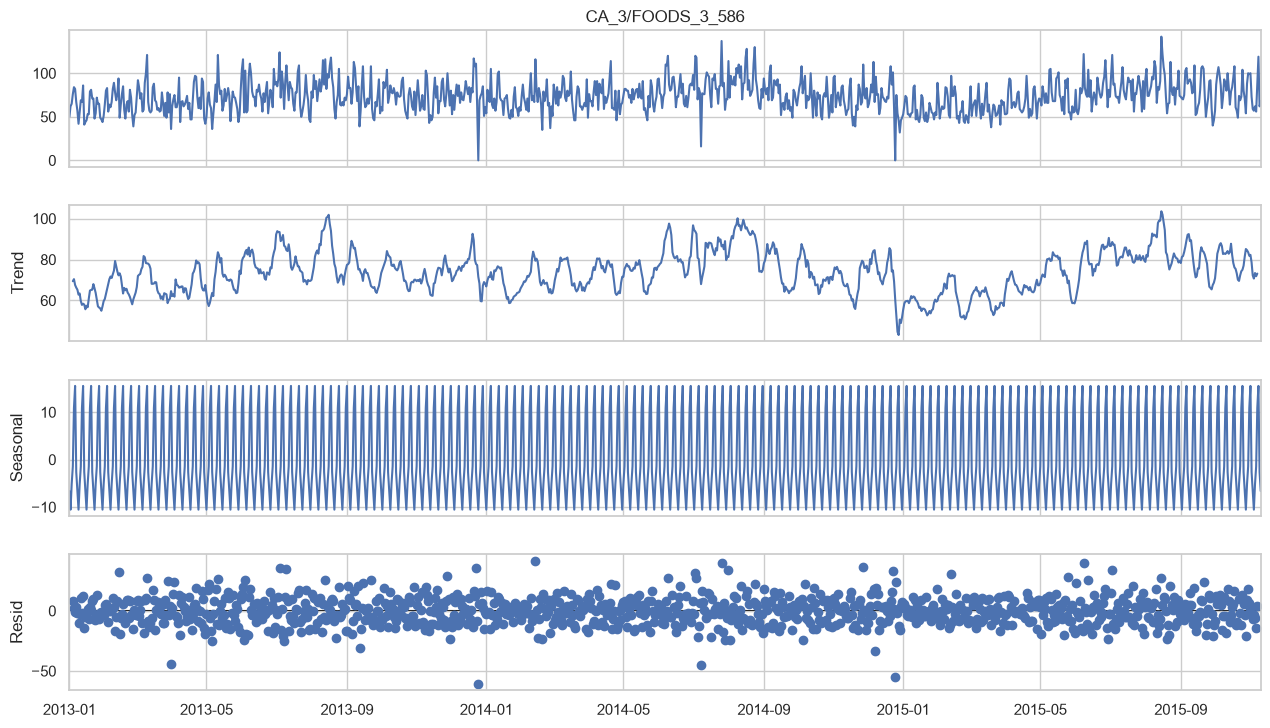

Efecto de cada día (unidades): {'lun': -2.6, 'mar': -6.6, 'mié': -10.5, 'jue': -5.2, 'vie': -1.4, 'sáb': 10.9, 'dom': 15.5}
Días sin tendencia (NaN en los bordes): 6


In [10]:
clasica = seasonal_decompose(y, model="additive", period=7)
clasica.plot().set_size_inches(14, 8)
plt.show()

# Un valor fijo por día de la semana: cuántas unidades suma o resta ese día respecto a la tendencia
efecto_dia = clasica.seasonal.groupby(clasica.seasonal.index.day_of_week).first()
print("Efecto de cada día (unidades):", efecto_dia.rename(index=dict(enumerate(DIAS))).round(1).to_dict())
print("Días sin tendencia (NaN en los bordes):", clasica.trend.isna().sum())

### 2.3 STL: una descomposición más robusta
**STL** (*Seasonal-Trend decomposition using Loess*) hace lo mismo, pero mejor en dos cosas:
- **Robusta:** con `robust=True` le da menos peso a los días raros (como el 25 de diciembre), que en la clásica contaminan la estacionalidad.
- **Flexible:** deja que el patrón semanal cambie de a poco con el tiempo, en vez de forzarlo igual en los 3 años.

Para resumir cuánto pesa cada componente usamos la **fuerza** (Hyndman y Athanasopoulos, *Forecasting: Principles and Practice*, cap. 4):

`fuerza = 1 − var(residuo) / var(componente + residuo)`

Va de 0 a 1. Cerca de 0, el componente se pierde en el ruido; cerca de 1, domina. Como referencia práctica, por encima de ~0,6 se considera fuerte.

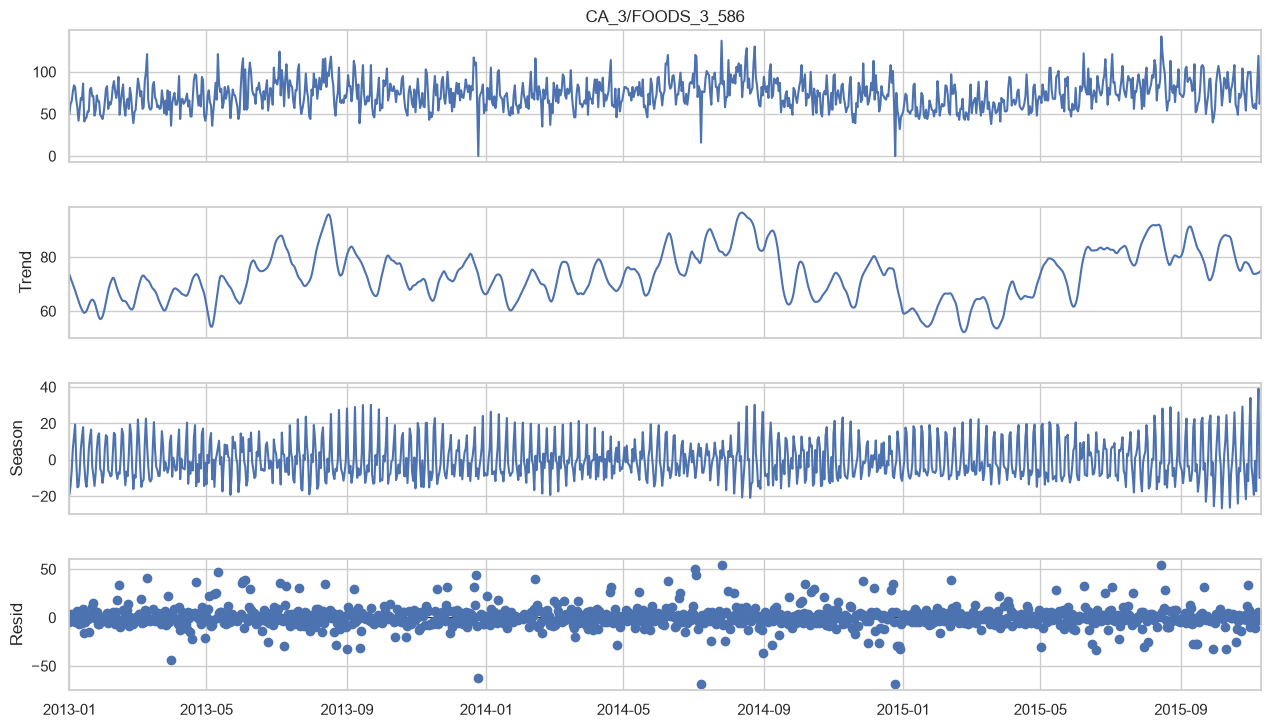

Fuerza estacional semanal: 0.45
Fuerza de la tendencia:    0.41


In [11]:
def fuerza(componente, residuo):
    """Fuerza de un componente (0 = se pierde en el ruido, 1 = domina)."""
    return max(0.0, 1 - residuo.var() / (componente + residuo).var())


stl = STL(y, period=7, robust=True).fit()
stl.plot().set_size_inches(14, 8)
plt.show()

print("Fuerza estacional semanal:", round(fuerza(stl.seasonal, stl.resid), 2))
print("Fuerza de la tendencia:   ", round(fuerza(stl.trend, stl.resid), 2))

Con un solo período (7), la "tendencia" de STL no es una línea recta: sube en verano y baja en invierno. **Está absorbiendo la estacionalidad anual**, porque nadie le dijo que existía.

### 2.4 ¿Y la estacionalidad anual?
`MSTL` (*Multiple STL*) acepta varios períodos a la vez. Le pedimos 7 y 365

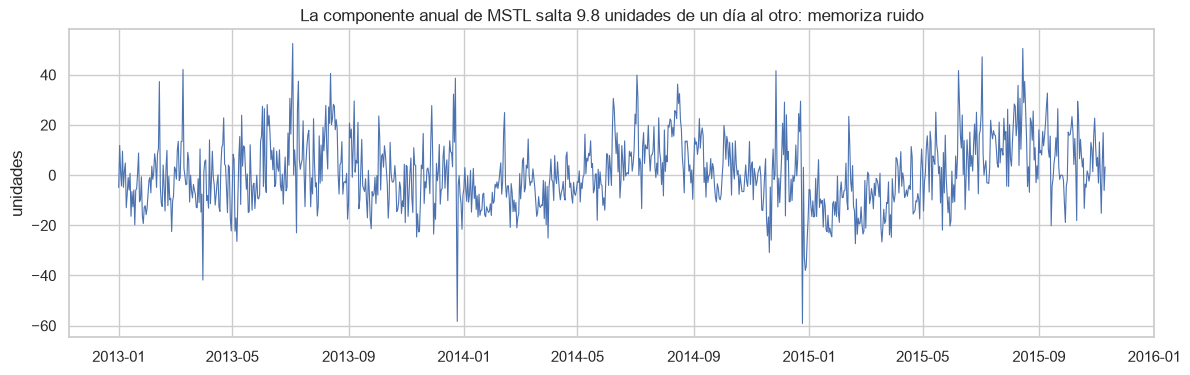

Años de datos: 2.86
Salto medio de un día al siguiente: 9.8 unidades
Días con mayor efecto anual:
date
2014-12-25    59.1
2013-12-25    58.3
2013-07-04    52.5
2015-08-15    50.5
2015-07-03    47.1
Name: seasonal_365, dtype: float64


In [12]:
mstl = MSTL(y, periods=(7, 365)).fit()
anual = mstl.seasonal["seasonal_365"]

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(anual.index, anual, lw=0.8)
ax.set_title(f"La componente anual de MSTL salta {anual.diff().abs().mean():.1f} unidades de un día al otro: memoriza ruido")
ax.set_ylabel("unidades")
plt.show()

print("Años de datos:", round(len(y) / 365, 2))
print("Salto medio de un día al siguiente:", round(anual.diff().abs().mean(), 1), "unidades")
print("Días con mayor efecto anual:")
print(anual.abs().nlargest(5).round(1))

**Esto NO es una estacionalidad anual creíble.** Una curva anual real (más ventas en verano) debería cambiar despacio. Esta salta varias unidades de un día al siguiente, y sus valores más extremos son días sueltos: los dos 25 de diciembre (cerca de −59) y el 4 de julio de 2013 (+52).

¿Por qué pasa? Con 2,86 años de datos, cada día del calendario aparece solo 2 o 3 veces. Al estimar "el efecto del 25 de diciembre" con dos observaciones, el método copia lo que pasó esos dos días. Esto se llama **sobreajuste** (*overfitting*): el modelo memoriza el ruido en vez de aprender el patrón.

La alternativa es describir la forma anual con unas pocas curvas suaves, los **términos de Fourier**: pares seno/coseno con período de un año. Con `K` pares, la curva solo puede tener forma suave (con `K = 2` puede tener hasta dos subidas y dos bajadas por año), y se estiman `2K` números en vez de 365. La comparamos contra la media móvil de 7 días, que ya no tiene el ciclo semanal.

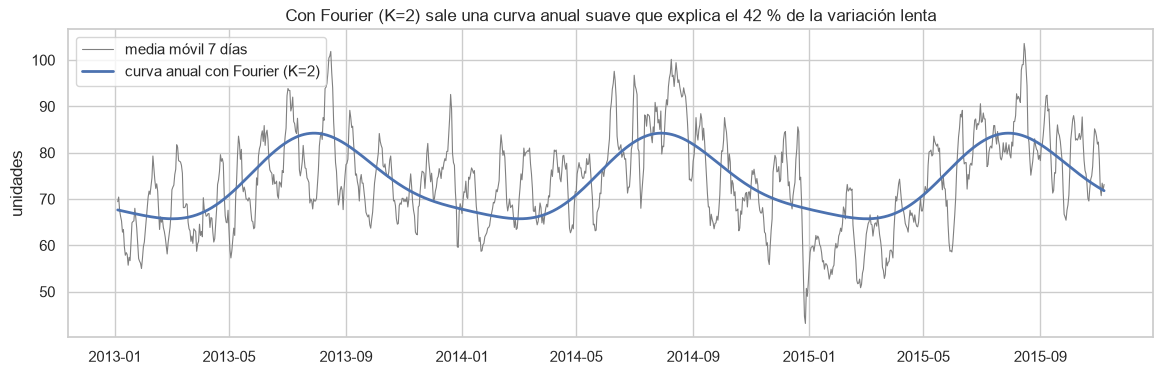

Rango de la curva anual: 18.5 unidades
Variación lenta que explica (R²): 0.42


In [13]:
def terminos_fourier(indice, periodo=365.25, K=2):
    """Pares seno/coseno del día del año. Sirven como variables externas para SARIMAX (paso 5)."""
    t = indice.day_of_year.to_numpy()
    columnas = {}
    for k in range(1, K + 1):
        columnas[f"sin_{k}"] = np.sin(2 * np.pi * k * t / periodo)
        columnas[f"cos_{k}"] = np.cos(2 * np.pi * k * t / periodo)
    return pd.DataFrame(columnas, index=indice)


suave = y.rolling(7, center=True).mean().dropna()   # serie sin ciclo semanal
X = terminos_fourier(suave.index, K=2)
X.insert(0, "const", 1.0)
# Regresión lineal común: busca la combinación de senos/cosenos que mejor sigue a la serie suavizada
coef, *_ = np.linalg.lstsq(X.to_numpy(), suave.to_numpy(), rcond=None)
curva_anual = pd.Series(X.to_numpy() @ coef, index=suave.index)

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(suave.index, suave, lw=0.8, color="grey", label="media móvil 7 días")
ax.plot(curva_anual.index, curva_anual, lw=2, label="curva anual con Fourier (K=2)")
ax.set_ylabel("unidades")
ax.legend(loc="upper left")
r2_anual = 1 - (suave - curva_anual).var() / suave.var()
ax.set_title(f"Con Fourier (K=2) sale una curva anual suave que explica el {100 * r2_anual:.0f} % de la variación lenta")
plt.show()

print("Rango de la curva anual:", round(curva_anual.max() - curva_anual.min(), 1), "unidades")
print("Variación lenta que explica (R²):", round(1 - (suave - curva_anual).var() / suave.var(), 2))

> **Conclusión:** SARIMA va a modelar el ciclo **semanal** (`s = 7`); el ciclo **anual** entra como términos de **Fourier** en un `SARIMAX` (DEC-009).

**Evidencia:**
- **Aditiva:** la amplitud semanal no crece con el nivel (correlación 0,11), así que la descomposición aditiva es la correcta.
- **Ciclo semanal:** según la descomposición clásica, el domingo suma unas 15,5 unidades a la tendencia, el sábado 10,9, y el miércoles resta 10,5. Con STL, la fuerza estacional semanal es 0,45: moderada, porque el residuo todavía tiene mucho ruido diario.
- **Tendencia:** con STL de un solo período, la "tendencia" (fuerza 0,41) incluye la ola anual.
- **Ciclo anual:** existe (verano alto, enero bajo), pero **no se puede estimar día por día** con menos de 3 años de datos. MSTL sobreajusta: su componente anual salta en promedio 9,8 unidades de un día al siguiente y copia los 25 de diciembre y el 4 de julio de 2013. Con 2 pares de Fourier sale una curva suave de 18,5 unidades de rango, que explica el 42 % de la variación lenta (la media móvil de 7 días).
- Un SARIMA con `s = 365` sobre datos diarios es inviable: tendría que estimar relaciones a 365 días de distancia con apenas 2,86 ciclos, y además es muy lento.

**Qué hacemos:** antes de seguir, tratar los dos 25 de diciembre ([2.5](#sec-2-5)), que ya contaminaron MSTL. Después, en el paso 3, ver si la serie es **estacionaria**.

<a id="sec-2-5"></a>

### 2.5 Tratar el 25 de diciembre antes de modelar
Los dos únicos ceros de la serie son los 25 de diciembre de 2013 y 2014: la tienda está **cerrada**, no es que nadie quiera comprar. Si se dejan así, el modelo los toma como demanda real. Ya vimos el efecto en 2.4: MSTL los copió como −59 unidades de "estacionalidad anual".

Dos opciones razonables:
- **Imputar:** reemplazar cada 25 de diciembre por el valor del mismo día de la semana anterior (`y[t-7]`).
- **Variable indicadora (*dummy*):** una columna que vale 1 ese día, como variable externa del `SARIMAX`.

Elegimos **imputar** (DEC-012). Los pasos 3 y 4 trabajan con la serie sola, sin variables externas, así que la indicadora recién podría entrar en el paso 5, y para entonces los tests y la ACF ya estarían contaminados. Imputar no cambia lo que se evalúa: `valid` (11-nov a 8-dic) y los cortes del backtesting no incluyen ningún 25 de diciembre. Para pronosticar un 25 de diciembre futuro alcanza con una regla: tienda cerrada = 0.

Desde acá trabajamos con **`y_modelo`**; `y` queda como la serie original.

In [14]:
def imputar_cierres(y, fechas, desfase=7):
    """Reemplaza los días de tienda cerrada por el valor del mismo día de la semana anterior.

    Falla si alguno de esos días no vale 0: entonces no sería un cierre y no hay que tocarlo.
    """
    fechas = pd.DatetimeIndex(fechas)
    if (y.loc[fechas] != 0).any():
        raise ValueError("Alguna de las fechas indicadas tiene ventas: no es un cierre")
    salida = y.copy()
    salida.loc[fechas] = y.loc[fechas - pd.Timedelta(days=desfase)].to_numpy()
    return salida


CIERRES = y.index[(y.index.month == 12) & (y.index.day == 25)]
y_modelo = imputar_cierres(y, CIERRES)
print("Ceros que quedan en y_modelo:", int((y_modelo == 0).sum()))
pd.DataFrame({"original": y.loc[CIERRES], "tratada (y[t-7])": y_modelo.loc[CIERRES]})

Ceros que quedan en y_modelo: 0


,original,tratada (y[t-7])
date,,
2013-12-25,0,67
2014-12-25,0,73


> **Conclusión:** la serie de trabajo `y_modelo` ya no tiene ceros: los dos 25 de diciembre valen ahora lo mismo que el día equivalente de la semana anterior.

**Evidencia:**
- Los dos 25 de diciembre valían 0 y pasan a 67 (2013) y 73 (2014): lo que se vendió el 18 de diciembre de cada año.
- Es el único cambio: los otros 1.042 días quedan iguales.

**Qué hacemos:** usar `y_modelo` en los pasos 3, 4 y 5. El tratamiento del 25 de diciembre para el resto de las series sigue pendiente en `decisions.md`.

<a id="sec-3"></a>

## 3. Estacionariedad — parte A: diagnóstico

El paso 3 está dividido en dos partes. En esta (A) diagnosticamos si la serie original es estacionaria. En la parte B la vamos a diferenciar y a decidir cuántas diferencias necesita el modelo.

### 3.1 La idea
ARIMA aprende reglas del tipo "las ventas de hoy se parecen en tal proporción a las de ayer". Para que una regla aprendida con datos de 2013 sirva para predecir 2015, esa regla tiene que valer en todo el período. A esa propiedad se la llama **estacionariedad**.

Una serie es estacionaria cuando, a grandes rasgos, tres cosas no cambian con el tiempo:
1. **La media:** no hay tendencia; la serie oscila alrededor de un mismo nivel.
2. **La variabilidad (varianza):** las oscilaciones tienen más o menos el mismo tamaño en cualquier época.
3. **La relación entre un día y los anteriores (autocorrelación):** depende de la distancia entre los días, no de la fecha.

Dos ejemplos de series **no** estacionarias: una con tendencia (la media sube año a año) y una con estacionalidad (la media del domingo es distinta de la del miércoles: depende de qué día mires).

### 3.2 Mirarla primero
Este gráfico mira la serie **original** `y`: el tratamiento de 2.5 cambia solo 2 días de 1.044 y no se nota con una ventana de 91 días.

Antes de cualquier test, graficamos la **media y el desvío móviles** con una ventana larga, de 91 días (unas 13 semanas, un trimestre). La ventana larga borra el ciclo semanal y deja ver si el nivel o la variabilidad cambian a lo largo del tiempo.

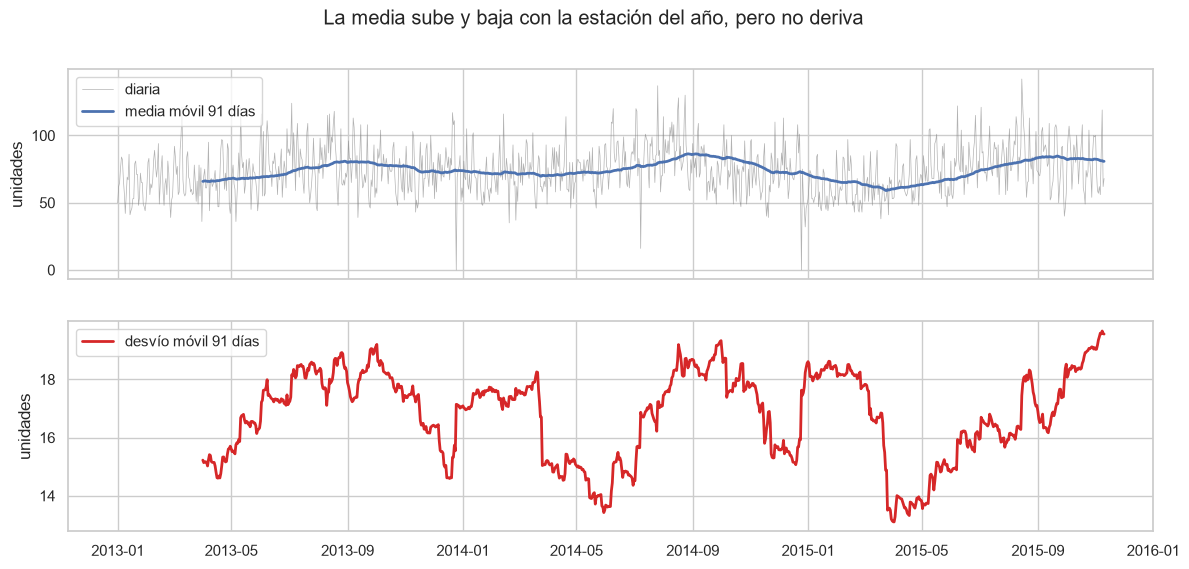

,mean,std
date,,
2013-01-01,65.9,15.3
2013-04-01,72.1,17.1
2013-07-01,79.2,19.0
2013-10-01,73.7,17.0
2014-01-01,70.2,15.3
2014-04-01,76.3,14.4
2014-07-01,83.5,19.3
2014-10-01,71.2,18.5
2015-01-01,60.3,13.2


In [15]:
def graficar_media_desvio_movil(y, ventana=91, titulo="¿Cambian la media y la variabilidad con el tiempo?"):
    """Serie con su media y desvío móviles. Si la serie fuera estacionaria, las dos líneas serían casi planas."""
    fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
    axes[0].plot(y.index, y, lw=0.5, color="grey", alpha=0.6, label="diaria")
    axes[0].plot(y.index, y.rolling(ventana).mean(), lw=2, label=f"media móvil {ventana} días")
    axes[0].set_ylabel("unidades")
    axes[0].legend(loc="upper left")
    axes[1].plot(y.index, y.rolling(ventana).std(), lw=2, color="tab:red", label=f"desvío móvil {ventana} días")
    axes[1].set_ylabel("unidades")
    axes[1].legend(loc="upper left")
    fig.suptitle(titulo)
    plt.show()


graficar_media_desvio_movil(y, titulo="La media sube y baja con la estación del año, pero no deriva")

# Lo mismo en números: media y desvío por trimestre
y.resample("QS").agg(["mean", "std"]).round(1)

### 3.3 Los tests: ADF y KPSS
Los corremos sobre la serie original y sobre `y_modelo`, para ver si el tratamiento de 2.5 cambia la conclusión.

A ojo se ve que la media se mueve, pero ¿alcanza para decir que la serie no es estacionaria? Para eso hay tests estadísticos. Se usan dos, porque plantean la pregunta al revés y se complementan:

| Test | Hipótesis nula (H0) | p < 0,05 significa |
|---|---|---|
| **ADF** (*Augmented Dickey-Fuller*) | La serie **no** es estacionaria: tiene una "raíz unitaria" | Rechazo H0 → **estacionaria** |
| **KPSS** (Kwiatkowski-Phillips-Schmidt-Shin) | La serie **sí** es estacionaria alrededor de un nivel | Rechazo H0 → **no estacionaria** |

**¿Qué es una raíz unitaria?** Es el caso de una serie que no tiene un nivel al que volver: cada día es el anterior más un cambio al azar, como un paseo aleatorio (el precio de una acción es el ejemplo clásico). Si un día sube, se queda arriba. Una serie estacionaria, en cambio, después de un día raro vuelve a su nivel. ADF pregunta: "¿esta serie es un paseo aleatorio?".

**¿Por qué dos tests?** Un test de hipótesis solo puede rechazar su H0; no rechazarla no prueba que sea cierta, puede ser que falten datos. Con hipótesis opuestas, si los dos apuntan al mismo lado la conclusión es firme. Si se contradicen, la serie está en una zona gris y hay que mirar más.

Una limitación: **ninguno de los dos está diseñado para detectar estacionalidad**. Miden sobre todo si hay tendencia o deriva. La estacionalidad se juzga con los gráficos y, en el paso 4, con la autocorrelación en los retardos 7, 14 y 21.

In [16]:
def test_estacionariedad(y, nombre=None, alfa=0.05):
    """Corre ADF y KPSS sobre una serie y devuelve una fila con los resultados y su lectura.

    ADF:  H0 = la serie NO es estacionaria (tiene raíz unitaria). p < alfa -> estacionaria.
    KPSS: H0 = la serie SÍ es estacionaria alrededor de un nivel. p < alfa -> no estacionaria.
    Se va a reutilizar en la parte B sobre las series diferenciadas.
    """
    y = y.dropna()   # al diferenciar aparecen NaN al principio
    adf_stat, adf_p, adf_lags, *_ = adfuller(y, autolag="AIC", result_object=False)   # elige cuántos retardos usar con AIC
    with warnings.catch_warnings():
        # KPSS solo tabula p entre 0,01 y 0,10: fuera de ese rango devuelve el borde (0,10 significa "0,10 o más")
        warnings.simplefilter("ignore", InterpolationWarning)
        kpss_stat, kpss_p, kpss_lags, _ = kpss(y, regression="c", nlags="auto", result_object=False)   # "c" = alrededor de un nivel fijo
    return pd.DataFrame({
        "adf_estadistico": [adf_stat],
        "adf_p": [adf_p],
        "adf_retardos": [adf_lags],
        "kpss_estadistico": [kpss_stat],
        "kpss_p": [kpss_p],
        "adf_dice": ["estacionaria" if adf_p < alfa else "no estacionaria"],
        "kpss_dice": ["no estacionaria" if kpss_p < alfa else "estacionaria"],
    }, index=[nombre or y.name]).round(4)


pd.concat([test_estacionariedad(y, nombre="original"), test_estacionariedad(y_modelo, nombre="y_modelo (sin 25-dic)")])

,adf_estadistico,adf_p,adf_retardos,kpss_estadistico,kpss_p,adf_dice,kpss_dice
original,-3.5691,0.0064,21,0.4186,0.0691,estacionaria,estacionaria
y_modelo (sin 25-dic),-3.5728,0.0063,21,0.4000,0.0771,estacionaria,estacionaria


> **Conclusión:** la serie **no tiene tendencia ni deriva**: se parte de `d = 0` (DEC-010). Lo que no es estacionario es el **ciclo semanal**, que los tests no miden.

**Evidencia:**
- **A ojo:** el nivel no deriva a lo largo de los tres años (72,4 de media en la primera mitad, 75,2 en la segunda), pero sube y baja con la estación del año: la media por trimestre va de 60,3 (primer trimestre de 2015) a 83,5 (tercer trimestre de 2014). El desvío trimestral se mueve entre 13,2 y 19,3, y es más alto en los trimestres de nivel alto.
- **ADF:** estadístico −3,57 contra un valor crítico de −2,86 al 5 %, p = 0,006. Se rechaza la raíz unitaria: la serie no es un paseo aleatorio, siempre vuelve a su nivel.
- **KPSS:** estadístico 0,419 contra 0,463 al 5 % y 0,347 al 10 %, p ≈ 0,07. No se rechaza la estacionariedad al 5 %, pero sí al 10 %. Es un caso límite.
- **Con `y_modelo`** (sin los 25 de diciembre) casi nada cambia: ADF −3,57 (p = 0,006) y KPSS 0,400 (p ≈ 0,08). El tratamiento no cambia la conclusión.
- **Lectura conjunta:** los dos tests coinciden en lo importante, que **no hay tendencia ni deriva**. El KPSS en el límite está detectando que la media no es del todo constante, y sabemos por qué: el ciclo semanal y la ola anual, que estos tests no están diseñados para medir.
- **Detalle:** ADF eligió 21 retardos, justo 3 semanas. Para dejar residuos limpios tuvo que "comerse" el ciclo semanal con retardos. Es otra señal de que el ciclo semanal es la estructura dominante.

**Qué hacemos:** en la parte B, aplicar a `y_modelo` la diferencia estacional (`y[t] − y[t−7]`), y también la simple para comparar, y repetir estos tests y gráficos para decidir `d` y `D`. La ola anual no se diferencia: queda para los términos de Fourier (DEC-009).

<a id="sec-3b"></a>

## 3. Estacionariedad — parte B: diferenciar

### 3.4 La idea
**Diferenciar** es reemplazar cada valor por su cambio respecto de un día anterior. Hay dos tipos:

| Diferencia | Fórmula | Qué borra | Orden en SARIMA |
|---|---|---|---|
| **Simple** | `y[t] − y[t−1]` | Una tendencia o una deriva: el nivel que se mueve de a poco | `d` |
| **Estacional** | `y[t] − y[t−7]` | Un patrón que se repite cada 7 días: compara cada día con el mismo día de la semana anterior | `D` |

Un ejemplo con esta serie: si el domingo pasado se vendieron 95 y este domingo 90, la diferencia estacional vale −5. El "domingo vende más" desaparece, porque se compara domingo contra domingo.

**Cuidado con diferenciar de más (*sobrediferenciación*).** Cada diferencia que no hace falta agrega ruido y deja una huella: una autocorrelación **negativa fuerte**, cerca de −0,5, en el retardo que se diferenció (1 para `d`, 7 para `D`). Por eso no alcanza con que los tests digan "estacionaria": hay que elegir **la menor cantidad de diferencias** que deja la serie estacionaria.

Probamos las cuatro combinaciones sobre `y_modelo` y miramos tres cosas en cada una:
1. Los tests ADF y KPSS (la misma función de 3.3).
2. La autocorrelación en los retardos 1, 7 y 14: si el ciclo semanal sigue ahí (valores altos en 7 y 14) o si diferenciamos de más (valores cerca de −0,5).
3. El desvío: diferenciar de más suele **aumentarlo**.

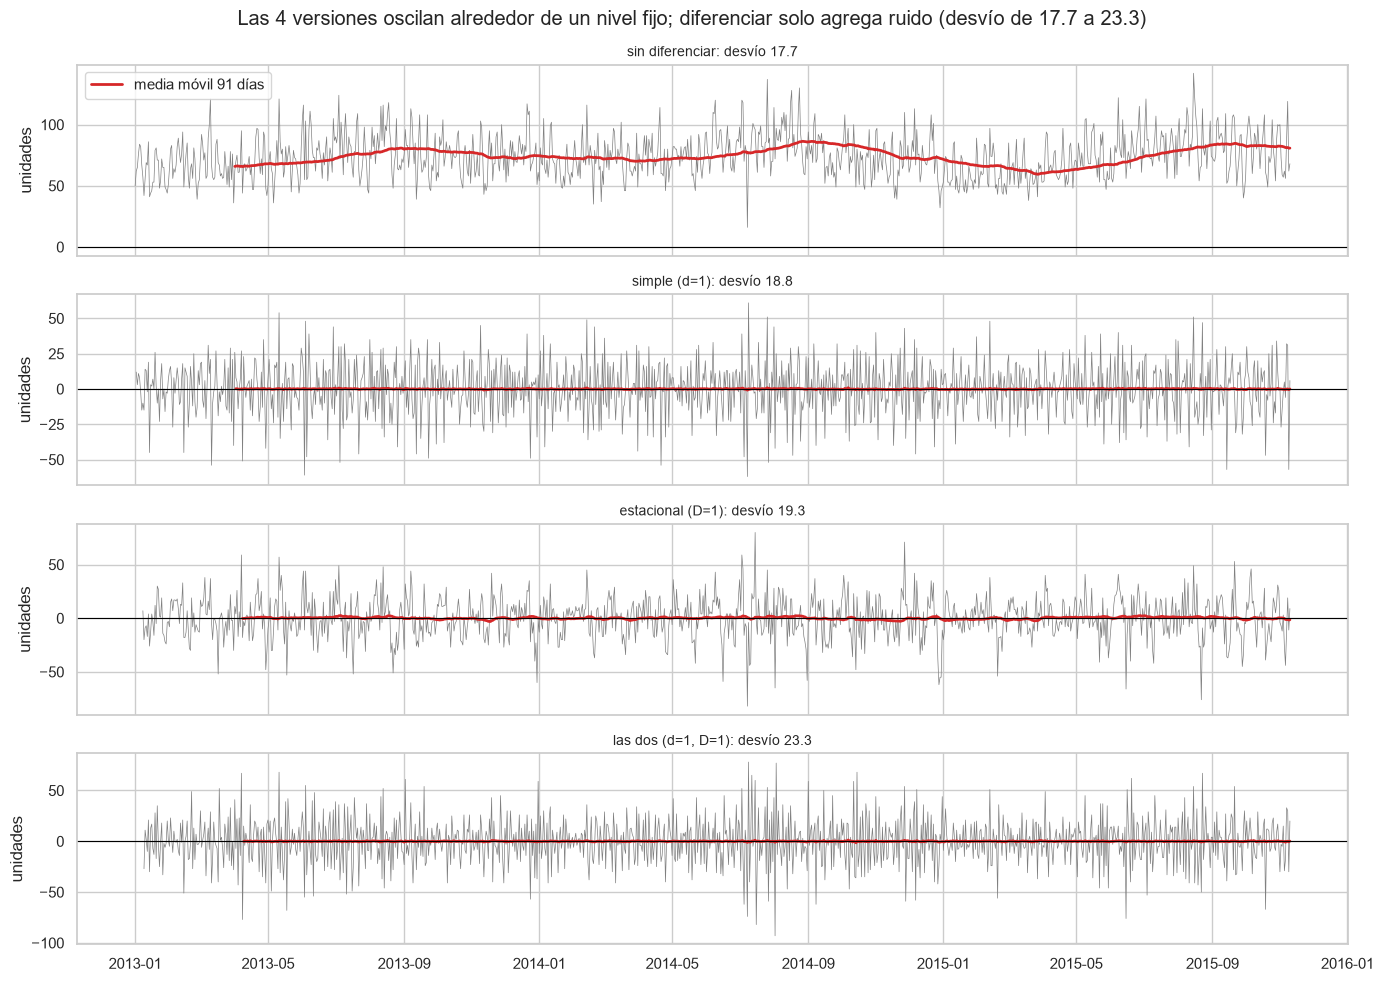

In [17]:
def diferenciar(y, d=0, D=0, s=7):
    """Aplica D diferencias estacionales (período s) y después d diferencias simples. Quita los NaN del inicio."""
    salida = y.copy()
    for _ in range(D):
        salida = salida.diff(s)
    for _ in range(d):
        salida = salida.diff(1)
    return salida.dropna()


VERSIONES = {"sin diferenciar": (0, 0), "simple (d=1)": (1, 0), "estacional (D=1)": (0, 1), "las dos (d=1, D=1)": (1, 1)}
series_dif = {nombre: diferenciar(y_modelo, d, D) for nombre, (d, D) in VERSIONES.items()}

fig, axes = plt.subplots(len(series_dif), 1, figsize=(14, 10), sharex=True)
for ax, (nombre, s) in zip(axes, series_dif.items()):
    ax.plot(s.index, s, lw=0.5, color="grey")
    ax.plot(s.index, s.rolling(91).mean(), lw=2, color="tab:red", label="media móvil 91 días")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"{nombre}: desvío {s.std():.1f}", fontsize=10)
    ax.set_ylabel("unidades")
axes[0].legend(loc="upper left")
desvios = [s.std() for s in series_dif.values()]
fig.suptitle(f"Las 4 versiones oscilan alrededor de un nivel fijo; diferenciar solo agrega ruido (desvío de {desvios[0]:.1f} a {max(desvios):.1f})")
plt.tight_layout(); plt.show()

In [18]:
def resumen_diferenciacion(series, rezagos=(1, 7, 14)):
    """Por versión: tests ADF/KPSS, autocorrelación en `rezagos` y desvío."""
    filas = []
    for nombre, s in series.items():
        fila = test_estacionariedad(s, nombre=nombre)
        ac = acf(s, nlags=max(rezagos), fft=True)
        for k in rezagos:
            fila[f"acf_{k}"] = round(ac[k], 3)
        fila["desvio"] = round(s.std(), 1)
        filas.append(fila)
    return pd.concat(filas)


tabla_dif = resumen_diferenciacion(series_dif)
tabla_dif[["adf_p", "kpss_p", "adf_dice", "kpss_dice", "acf_1", "acf_7", "acf_14", "desvio"]]

,adf_p,kpss_p,adf_dice,kpss_dice,acf_1,acf_7,acf_14,desvio
sin diferenciar,0.0063,0.0771,estacionaria,estacionaria,0.434,0.405,0.345,17.7
simple (d=1),0.0000,0.1000,estacionaria,estacionaria,-0.293,0.231,0.263,18.8
estacional (D=1),0.0000,0.1000,estacionaria,estacionaria,0.270,-0.451,-0.063,19.3
"las dos (d=1, D=1)",0.0000,0.1000,estacionaria,estacionaria,-0.457,-0.520,0.063,23.3


### 3.5 ¿Hace falta la diferencia estacional?
Los tests de 3.3 ya decían que la serie original es estacionaria en nivel, pero no miden el ciclo semanal. Para eso miramos la autocorrelación en los retardos 7, 14, 21, 28…: si baja **despacio** de un múltiplo de 7 al siguiente, el ciclo semanal es persistente y conviene la diferencia estacional. Si baja rápido, alcanza con modelarlo con términos estacionales del SARIMA (`P`, `Q`) sin diferenciar.

Una segunda referencia es la regla de Hyndman y Athanasopoulos (*Forecasting: Principles and Practice*, cap. 9): aplicar `D = 1` si la **fuerza estacional** (la de 2.3) supera 0,64.

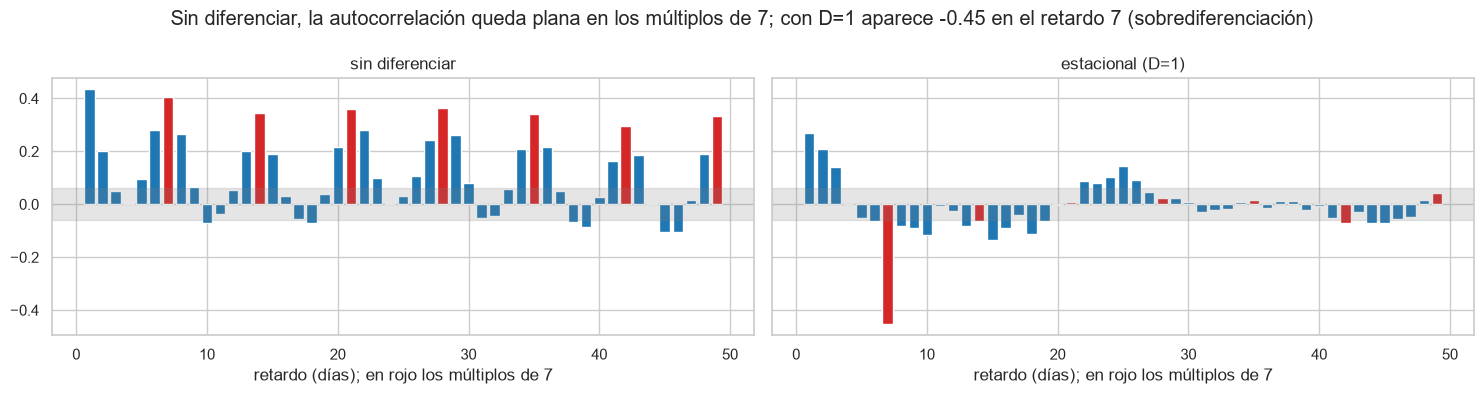

Autocorrelación de y_modelo en los múltiplos de 7: {7: 0.4, 14: 0.35, 21: 0.36, 28: 0.36, 35: 0.34, 42: 0.29, 49: 0.33}
Fuerza estacional semanal de y_modelo: 0.46 (regla: D = 1 si supera 0,64)


In [19]:
rezagos = np.arange(1, 50)
banda_acf = 1.96 / np.sqrt(len(y_modelo))
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for ax, nombre in zip(axes, ["sin diferenciar", "estacional (D=1)"]):
    valores = acf(series_dif[nombre], nlags=rezagos.max(), fft=True)[1:]
    ax.bar(rezagos, valores, color=["tab:red" if k % 7 == 0 else "tab:blue" for k in rezagos])
    ax.axhspan(-banda_acf, banda_acf, color="gray", alpha=0.2)
    ax.set_title(nombre); ax.set_xlabel("retardo (días); en rojo los múltiplos de 7")
ac7_D = acf(series_dif["estacional (D=1)"], nlags=7, fft=True)[7]
fig.suptitle(f"Sin diferenciar, la autocorrelación queda plana en los múltiplos de 7; con D=1 aparece {ac7_D:.2f} en el retardo 7 (sobrediferenciación)")
plt.tight_layout(); plt.show()

ac_original = acf(y_modelo, nlags=49, fft=True)
print("Autocorrelación de y_modelo en los múltiplos de 7:", {k: round(float(ac_original[k]), 2) for k in (7, 14, 21, 28, 35, 42, 49)})
stl_modelo = STL(y_modelo, period=7, robust=True).fit()
print("Fuerza estacional semanal de y_modelo:", round(fuerza(stl_modelo.seasonal, stl_modelo.resid), 2), "(regla: D = 1 si supera 0,64)")

> **Conclusión:** **no hace falta diferenciar**: `d = 0` y `D = 0` (DEC-013). El ciclo semanal es **fijo** (cada día de la semana suma siempre más o menos lo mismo), así que se modela con los términos estacionales del SARIMA (`P`, `Q` con `s = 7`) en vez de restarlo. `D = 1` queda como alternativa para comparar en el backtesting.

**Evidencia:**
- **Los tests no alcanzan para elegir:** las cuatro versiones salen estacionarias en ADF (p ≤ 0,006) y en KPSS (p = 0,077 sin diferenciar; en las diferenciadas el estadístico queda fuera de la tabla, o sea p > 0,10).
- **`d = 1` sobra:** deja una autocorrelación de −0,29 en el retardo 1 y sube el desvío de 17,7 a 18,8. Confirma `d = 0` (DEC-010).
- **`D = 1` deja la huella de la sobrediferenciación:** autocorrelación de −0,45 en el retardo 7, cerca del −0,5 típico, y el desvío sube a 19,3. Con las dos diferencias es peor: −0,46 en el retardo 1, −0,52 en el 7 y desvío 23,3.
- **La regla de Hyndman también dice `D = 0`:** la fuerza estacional semanal de `y_modelo` es 0,46, por debajo de 0,64.
- **El argumento a favor de `D = 1`:** sin diferenciar, la autocorrelación en los múltiplos de 7 casi no baja (0,40 en el retardo 7, 0,33 en el 49). Pero eso es justamente lo que produce un ciclo **fijo**: si el domingo siempre suma unas 15 unidades (2.2), cada domingo se parece a todos los anteriores, estén a 1 o a 7 semanas. La diferencia estacional es para un ciclo que **cambia de forma al azar** con el tiempo; aplicada a un ciclo fijo, lo borra y deja el −0,45 en el retardo 7.

**Qué hacemos:** el modelo base es un SARIMA(p, 0, q)(P, 0, Q)₇. En el paso 4 se leen la ACF y la PACF de `y_modelo` **sin diferenciar** para elegir `p`, `q`, `P` y `Q`. En el paso 5 se compara en el backtesting contra la misma especificación con `D = 1`.

<a id="sec-4a"></a>

## 4. ACF y PACF — parte A: retardos cortos (`p` y `q`)

El paso 4 también está partido en dos. En esta parte (A) leemos los primeros retardos para elegir la parte **no estacional** del modelo: `p` (cuántos días anteriores entran directo) y `q` (cuántos errores anteriores entran). En la parte B se leen los múltiplos de 7 para elegir `P` y `Q`.

### 4.1 Qué se mira

Los gráficos se leen sobre `y_modelo` **sin diferenciar**, que es la forma en que se va a modelar (DEC-013). Las reglas de lectura están en la sección 8 del documento de fundamentos:
- Si la **PACF se corta** de golpe después del retardo *p* y la **ACF decae** de a poco, sugiere un componente **AR** de orden *p*.
- Si la **ACF se corta** de golpe después del retardo *q* y la **PACF decae** de a poco, sugiere un componente **MA** de orden *q*.

Los retardos cortos describen cómo depende un día de los días inmediatamente anteriores. El ciclo semanal empieza a notarse más adelante, así que acá nos concentramos en los retardos 1 a 4 y dejamos lo que pasa desde el 5 para la parte B. Las barras rojas del gráfico son los múltiplos de 7.

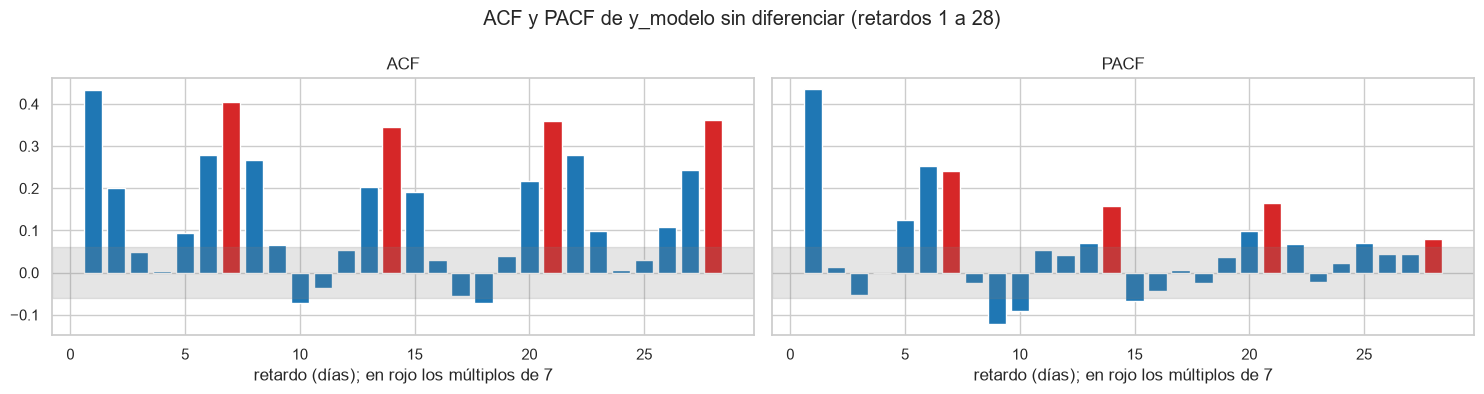

Franja de confianza: ±0.061
          acf  pacf  acf_fuera  pacf_fuera
retardo                                   
1        0.43  0.43       True        True
2        0.20  0.01       True       False
3        0.05 -0.05      False       False
4        0.00 -0.00      False       False
5        0.09  0.12       True        True
6        0.28  0.25       True        True
Si fuera un AR(1) puro, la ACF en el retardo 2 sería ACF(1)² = 0.19; la observada es 0.20


In [22]:
def tabla_acf_pacf(y, nlags=49):
    """ACF y PACF de `y` en los retardos 1..nlags, y la franja de confianza (±1,96/√n)."""
    banda = 1.96 / np.sqrt(len(y))
    tabla = pd.DataFrame({"acf": acf(y, nlags=nlags, fft=True)[1:], "pacf": pacf(y, nlags=nlags)[1:]},
                         index=pd.RangeIndex(1, nlags + 1, name="retardo"))
    return tabla, banda


def graficar_acf_pacf(tabla, banda, titulo):
    """Dos paneles (ACF y PACF) con la franja de confianza; en rojo los múltiplos de 7."""
    fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
    for ax, col in zip(axes, ["acf", "pacf"]):
        ax.bar(tabla.index, tabla[col], color=["tab:red" if k % 7 == 0 else "tab:blue" for k in tabla.index])
        ax.axhspan(-banda, banda, color="gray", alpha=0.2)
        ax.set_title(col.upper()); ax.set_xlabel("retardo (días); en rojo los múltiplos de 7")
    fig.suptitle(titulo)
    plt.tight_layout(); plt.show()


tabla_ac, banda_ac = tabla_acf_pacf(y_modelo)
graficar_acf_pacf(tabla_ac.loc[:28], banda_ac, "ACF y PACF de y_modelo sin diferenciar (retardos 1 a 28)")

cortos = tabla_ac.loc[1:6].copy()
cortos["acf_fuera"] = cortos["acf"].abs() > banda_ac
cortos["pacf_fuera"] = cortos["pacf"].abs() > banda_ac
print(f"Franja de confianza: ±{banda_ac:.3f}")
print(cortos.round(2).to_string())
print(f"Si fuera un AR(1) puro, la ACF en el retardo 2 sería ACF(1)² = {tabla_ac.loc[1, 'acf'] ** 2:.2f}; la observada es {tabla_ac.loc[2, 'acf']:.2f}")

> **Conclusión:** en los retardos cortos la serie se lee como un **AR(1)**: punto de partida `p = 1` y `q = 0`. Como alternativas cercanas para comparar en el backtesting quedan `p = 1, q = 1` y `p = 2`.

**Evidencia:**
- **La PACF se corta después del retardo 1:** vale 0,43 en el retardo 1 y 0,01, −0,05 y 0,00 en los retardos 2, 3 y 4, los tres dentro de la franja (±0,06).
- **La ACF decae de a poco, como en un AR(1):** 0,43, 0,20, 0,05 y 0,00 en los retardos 1 a 4. Un AR(1) puro daría 0,43² = 0,19 en el retardo 2, y la observada es 0,20.
- **Por qué `q = 0`:** la ACF no se corta de golpe, decae. Esa es la forma de un AR; un MA tendría la ACF cortándose y la PACF decayendo.
- **Los retardos 5 y 6 no se leen acá:** quedan fuera de la franja (ACF 0,09 y 0,28), pero son el comienzo del ciclo semanal, que llega a 0,40 en el retardo 7. Se interpretan en la parte B.

**Qué hacemos:** `p = 1` y `q = 0` son un punto de partida, no la respuesta final. La lectura visual sirve para acotar candidatos; en el paso 5 se comparan con backtesting y AIC. En la parte B se leen los múltiplos de 7 para `P` y `Q`.

<a id="sec-4b"></a>

## 4. ACF y PACF — parte B: retardos estacionales (`P` y `Q`)

En la parte A elegimos la parte no estacional (`p = 1`, `q = 0`). Ahora miramos los mismos gráficos hasta el retardo 49, pero leyendo solo los **múltiplos de 7** (las barras rojas), que son los que describen cómo depende un día del mismo día de las semanas anteriores.

### 4.2 Qué se mira

Las reglas son las mismas de la parte A, aplicadas a los múltiplos de 7:
- Si la **PACF se corta** después del retardo 7·*P* y la ACF decae, sugiere un componente estacional **AR** de orden *P*.
- Si la **ACF se corta** después del retardo 7·*Q* y la PACF decae, sugiere un componente estacional **MA** de orden *Q*.

Al final se arma la lista de especificaciones candidatas (`GRILLA_ORDENES`) que se comparan en el paso 5. Se usa una lista corta porque la lectura visual rara vez da una única respuesta, y comparar pocas especificaciones con el backtesting es más barato y menos propenso a ajustarse al azar que probar todas las combinaciones posibles.

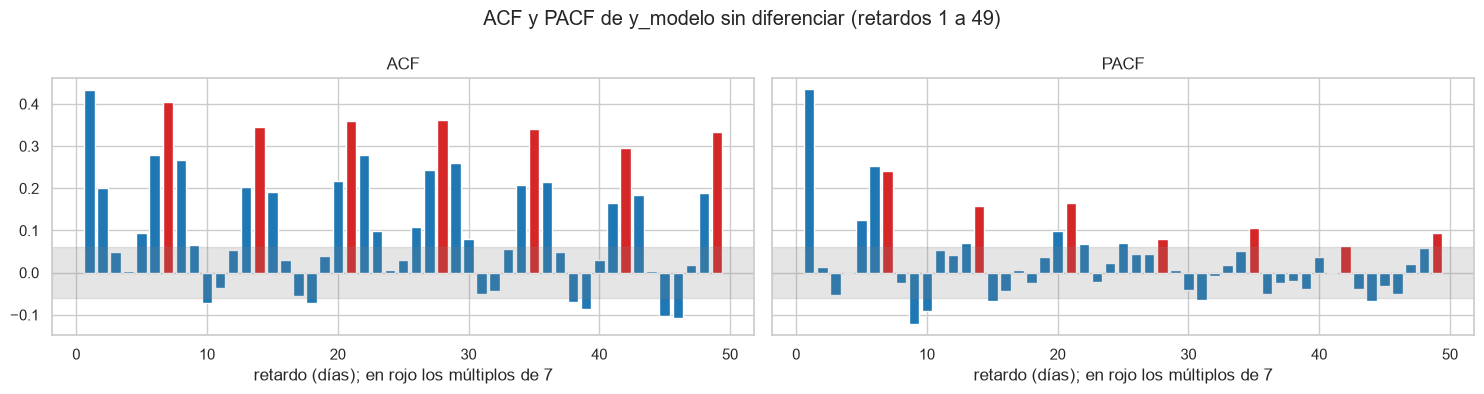

Franja de confianza: ±0.061

Múltiplos de 7:
          acf  pacf  acf_fuera  pacf_fuera
retardo                                   
7        0.40  0.24       True        True
14       0.35  0.16       True        True
21       0.36  0.17       True        True
28       0.36  0.08       True        True
35       0.34  0.11       True        True
42       0.29  0.06       True        True
49       0.33  0.09       True        True

Alrededor del retardo 7:
          acf  pacf
retardo            
5        0.09  0.12
6        0.28  0.25
7        0.40  0.24
8        0.27 -0.02
9        0.06 -0.12

Candidatos para el paso 5:
         nombre     order seasonal_order
           base (1, 0, 0)   (1, 0, 0, 7)
          q = 1 (1, 0, 1)   (1, 0, 0, 7)
          p = 2 (2, 0, 0)   (1, 0, 0, 7)
          Q = 1 (1, 0, 0)   (1, 0, 1, 7)
          P = 2 (1, 0, 0)   (2, 0, 0, 7)
D = 1 (DEC-013) (1, 0, 0)   (0, 1, 1, 7)


In [23]:
RETARDOS_ESTACIONALES = [7, 14, 21, 28, 35, 42, 49]

graficar_acf_pacf(tabla_ac, banda_ac, "ACF y PACF de y_modelo sin diferenciar (retardos 1 a 49)")

estacionales = tabla_ac.loc[RETARDOS_ESTACIONALES].copy()
estacionales["acf_fuera"] = estacionales["acf"].abs() > banda_ac
estacionales["pacf_fuera"] = estacionales["pacf"].abs() > banda_ac
print(f"Franja de confianza: ±{banda_ac:.3f}\n\nMúltiplos de 7:")
print(estacionales.round(2).to_string())
print("\nAlrededor del retardo 7:")
print(tabla_ac.loc[5:9].round(2).to_string())

# Candidatos para el paso 5, en el formato de SARIMAX: order=(p, d, q), seasonal_order=(P, D, Q, s)
GRILLA_ORDENES = [
    {"nombre": "base",            "order": (1, 0, 0), "seasonal_order": (1, 0, 0, 7)},
    {"nombre": "q = 1",           "order": (1, 0, 1), "seasonal_order": (1, 0, 0, 7)},
    {"nombre": "p = 2",           "order": (2, 0, 0), "seasonal_order": (1, 0, 0, 7)},
    {"nombre": "Q = 1",           "order": (1, 0, 0), "seasonal_order": (1, 0, 1, 7)},
    {"nombre": "P = 2",           "order": (1, 0, 0), "seasonal_order": (2, 0, 0, 7)},
    {"nombre": "D = 1 (DEC-013)", "order": (1, 0, 0), "seasonal_order": (0, 1, 1, 7)},
]
print("\nCandidatos para el paso 5:")
print(pd.DataFrame(GRILLA_ORDENES).to_string(index=False))

> **Conclusión:** en los retardos estacionales la serie pide un término `P`: punto de partida `P = 1` y `Q = 0`. Junto con la parte A, el SARIMA de partida es **(1, 0, 0)(1, 0, 0)₇**. La lectura no es nítida, así que el paso 5 compara una **lista corta de 6 candidatos** (`GRILLA_ORDENES`) con backtesting y AIC, y no solo el de partida.

**Evidencia:**
- **La ACF en los múltiplos de 7 no se corta ni decae:** 0,40, 0,35, 0,36, 0,36, 0,34, 0,29 y 0,33 entre los retardos 7 y 49. Es la meseta de un ciclo fijo (DEC-013); por eso no sirve para elegir `Q`, y `Q = 1` queda solo como alternativa.
- **La PACF en los múltiplos de 7 baja de a poco:** 0,24, 0,16, 0,17, 0,08, 0,11, 0,06 y 0,09, todos fuera de la franja (±0,06). El retardo 7 es el más fuerte, de ahí `P = 1`. Los retardos 14 y 21 (0,16 y 0,17) también pesan, y por eso `P = 2` queda como alternativa.
- **Los retardos 6 y 8 flanquean al 7:** la ACF vale 0,28, 0,40 y 0,27 en 6, 7 y 8, así que el pico semanal no cae de golpe y se reparte a los días vecinos. Lo tomamos como parte del ciclo semanal y no como un AR de orden 6. Si los residuos del modelo con `P = 1` dejan barras en los retardos 5 y 6, se revisa en el paso 5.

**Qué hacemos:** la lista incluye el modelo de partida, un cambio de uno en `q`, `p`, `Q` y `P` por vez, y la variante con `D = 1` que dejó abierta DEC-013 (con `(0, 1, 1)₇`, el complemento habitual de la diferencia estacional). **Riesgo a vigilar:** una ACF que se queda en 0,3 a 0,4 durante 49 retardos indica que el coeficiente estacional del `P = 1` puede salir cerca de 1; si el ajuste no converge o queda inestable, la alternativa es modelar el día de la semana con variables indicadoras en vez de términos estacionales.

<a id="sec-5a"></a>

## 5. Ajustar el SARIMA

El paso 5 se hace en tres partes:
- **A.** Ajustar los 6 candidatos de `GRILLA_ORDENES` sobre toda la serie y revisar que el ajuste funcione.
- **B.** Compararlos con el backtesting contra las líneas base (y elegir `K` de Fourier).
- **C.** Revisar los residuos del elegido y medirlo una sola vez en `valid`.

### 5.1 Parte A: ¿funcionan los 6 candidatos?

Ajustar un SARIMA es dejar que el modelo calcule sus coeficientes (cuánto pesa ayer, cuánto pesa el mismo día de la semana pasada, etc.). Acá todavía **no se elige ganador**: se revisa que cada candidato converja (que el cálculo termine bien) y que los coeficientes tengan sentido. Con `d = D = 0` se agrega una constante, porque la serie no tiene media cero; con `D = 1` no, porque la diferencia ya la absorbe.

Sobre lo que se ve en la tabla:
- `sigma` es el desvío del error de **un día adelante dentro de la muestra**. Sirve para comparar, pero no equivale al error a 28 días: eso lo mide la parte B.
- El AIC (menor = mejor ajuste, con penalización por complejidad) **no es comparable** entre `D = 0` y `D = 1`: el segundo pierde los primeros 7 días y no tiene constante.

In [24]:
from statsmodels.tsa.statespace.sarimax import SARIMAX


def ajustar_sarima(y, order, seasonal_order):
    """Ajusta un SARIMAX. Con d = D = 0 agrega una constante (la media de la serie no es cero); si diferencia, no."""
    trend = "c" if order[1] + seasonal_order[1] == 0 else None
    modelo = SARIMAX(y, order=order, seasonal_order=seasonal_order, trend=trend)
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        resultado = modelo.fit(disp=False, maxiter=200)
    return resultado, [str(a.message) for a in avisos]


filas, ajustes = [], {}
for cand in GRILLA_ORDENES:
    resultado, avisos = ajustar_sarima(y_modelo, cand["order"], cand["seasonal_order"])
    ajustes[cand["nombre"]] = resultado
    fila = {"candidato": cand["nombre"], "converge": bool(resultado.mle_retvals["converged"]),
            "avisos": len(avisos), "aic": resultado.aic}
    fila.update(resultado.params.drop("sigma2").round(2).to_dict())
    fila["sigma"] = resultado.params["sigma2"] ** 0.5
    filas.append(fila)

tabla_ajustes = pd.DataFrame(filas).set_index("candidato")
print(f"Ajuste sobre toda la serie y_modelo ({len(y_modelo)} días)\n")
print(tabla_ajustes.round(2).to_string(na_rep="-"))

Ajuste sobre toda la serie y_modelo (1044 días)

                 converge  avisos      aic  intercept  ar.L1  ar.S.L7  sigma  ma.L1  ar.L2  ma.S.L7  ar.S.L14
candidato                                                                                                    
base                 True       0  8645.05      32.10   0.36     0.32  15.14      -      -        -         -
q = 1                True       0  8640.40      22.81   0.54     0.34  15.09   -0.2      -        -         -
p = 2                True       0  8639.50      28.81   0.33     0.34  15.08      -   0.09        -         -
Q = 1                True       0  8480.10       0.76   0.36     0.98  13.94      -      -    -0.88         -
P = 2                True       0  8590.60      24.61   0.36     0.25  14.73      -      -        -      0.23
D = 1 (DEC-013)      True       0  8430.14          -   0.37        -  13.97      -      -    -0.90         -


> **Conclusión:** los 6 candidatos **convergen sin avisos**, así que el ajuste funciona. El de partida da `φ = 0,36` (ayer) y `Φ = 0,32` (mismo día de la semana anterior). Con `Q = 1`, el AR estacional sube a 0,98 y el MA estacional queda en −0,88: casi se cancelan.

**Evidencia:**
- **El riesgo anotado en 4B no aparece en el modelo de partida:** `Φ = 0,32`, lejos de 1. No hace falta recurrir a variables indicadoras por ahora.
- **`Q = 1` es el que más mejora:** AIC 8.480 contra 8.645 del de partida, y `sigma` 13,9 contra 15,1. `P = 2` mejora menos (AIC 8.591, `sigma` 14,7). `q = 1` y `p = 2` casi no cambian nada (AIC 8.640 y 8.640, `sigma` 15,1).
- **`Q = 1` y `D = 1` son casi el mismo modelo:** un AR estacional de 0,98 con un MA de −0,88 se parece a diferenciar con un MA de −0,90, y ambos tienen `sigma` ≈ 14,0. La mejora no viene de un coeficiente raro: indica que el patrón semanal **se mueve despacio** y no es del todo fijo. Esto matiza la lectura de la ACF de la parte 4B (ciclo fijo) y lo que se concluyó en el paso 3B, donde `D = 1` sin término MA empeoraba por sobrediferenciación.

**Qué hacemos:** pasar a la parte B con los 6 candidatos, sin descartar ninguno por este ajuste. Si el backtesting a 28 días confirma que `Q = 1` o `D = 1` ganan, hay que revisar la decisión de no diferenciar (DEC-013).

<a id="sec-5b"></a>

### 5.2 Parte B: ¿le gana a la línea base a 28 días?

Ahora se mide lo que importa. Para cada uno de los 6 cortes, el modelo se **vuelve a ajustar** con la historia hasta ese día, pronostica los 28 días siguientes y se compara con lo que pasó. Es el mismo MAE y los mismos 6 cortes de las líneas base (paso 1.6), así que los números se pueden comparar directo. Como son 6 ajustes por candidato, la celda tarda unos minutos.

Primero los 6 candidatos tal como están, sin la ola anual.

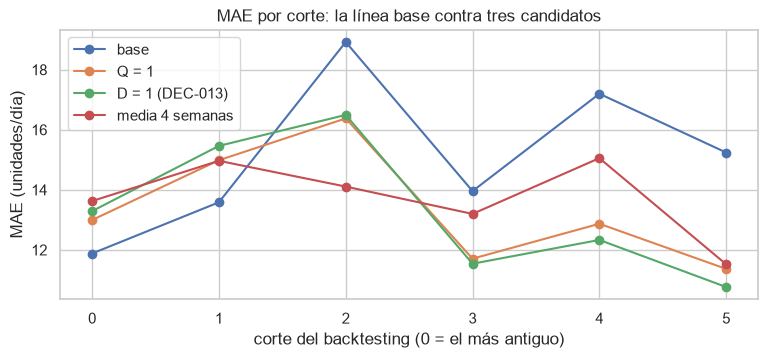

MAE por corte (unidades/día) de cada candidato:
corte               0     1     2     3     4     5
metodo                                             
base             11.9  13.6  18.9  14.0  17.2  15.2
q = 1            11.9  13.5  18.9  14.3  17.2  15.2
p = 2            11.9  13.5  18.9  14.2  17.1  15.2
Q = 1            13.0  15.0  16.4  11.7  12.9  11.4
P = 2            12.3  12.7  17.8  13.5  15.8  15.0
D = 1 (DEC-013)  13.3  15.5  16.5  11.5  12.3  10.8

Resumen (6 cortes de 28 días), ordenado por MAE medio:
                  mae_medio  mae_min  mae_max  mae_%_de_la_media  rmse_medio  rmse/mae
metodo                                                                                
D = 1 (DEC-013)        13.3     10.8     16.5               18.0        16.7       1.3
Q = 1                  13.4     11.4     16.4               18.1        16.7       1.2
media 4 semanas        13.7     11.5     15.1               18.6        17.5       1.3
P = 2                  14.5     12.3     17.8

In [25]:
# Los cortes del backtesting no incluyen ningún 25 de diciembre: evaluar sobre y_modelo equivale a evaluar sobre y
assert y_modelo.iloc[-N_CORTES * HORIZONTE:].equals(y.iloc[-N_CORTES * HORIZONTE:])


def metodo_sarima(order, seasonal_order, K=0):
    """Devuelve un `metodo(historia, horizonte)` para backtest: ajusta el SARIMA con la historia y pronostica.
    K > 0 agrega K pares de Fourier (ola anual) como variables externas."""
    def metodo(historia, horizonte):
        futuro = pd.date_range(historia.index[-1] + pd.Timedelta(days=1), periods=horizonte, freq=historia.index.freq)
        exog_h = terminos_fourier(historia.index, K=K) if K else None
        exog_f = terminos_fourier(futuro, K=K) if K else None
        trend = "c" if order[1] + seasonal_order[1] == 0 else None
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            ajuste = SARIMAX(historia, exog=exog_h, order=order, seasonal_order=seasonal_order, trend=trend).fit(disp=False, maxiter=200)
            return ajuste.forecast(horizonte, exog=exog_f).to_numpy()
    return metodo


def resumir(por_corte_df, referencia=y):
    """MAE y RMSE medios por método, más el MAE como % de la media de la serie."""
    r = por_corte_df.groupby(level=0, sort=False)["mae"].agg(mae_medio="mean", mae_min="min", mae_max="max")
    r["mae_%_de_la_media"] = 100 * r["mae_medio"] / referencia.mean()
    r["rmse_medio"] = por_corte_df.groupby(level=0, sort=False)["rmse"].mean()
    r["rmse/mae"] = r["rmse_medio"] / r["mae_medio"]
    return r


por_corte_sarima = pd.concat({c["nombre"]: backtest(y_modelo, metodo_sarima(c["order"], c["seasonal_order"]))
                              for c in GRILLA_ORDENES}, names=["metodo", "corte"])
comparacion = resumir(pd.concat([por_corte, por_corte_sarima])).sort_values("mae_medio")
print("MAE por corte (unidades/día) de cada candidato:")
print(por_corte_sarima["mae"].unstack("corte").round(1).to_string())
print("\nResumen (6 cortes de 28 días), ordenado por MAE medio:")
print(comparacion.round(1).to_string())

ax = por_corte_sarima["mae"].unstack("metodo")[["base", "Q = 1", "D = 1 (DEC-013)"]].join(
    por_corte["mae"].unstack("metodo")["media 4 semanas"]).plot(marker="o", figsize=(9, 3.5))
ax.set_title("MAE por corte: la línea base contra tres candidatos")
ax.set_xlabel("corte del backtesting (0 = el más antiguo)"); ax.set_ylabel("MAE (unidades/día)")
plt.show()

**Lectura:** solo `Q = 1` y `D = 1` bajan de la vara de 13,7 (13,4 y 13,3), y por muy poco: 0,3 o 0,4 unidades. Le ganan a la media de 4 semanas en 4 de los 6 cortes. El modelo de partida (15,1) es **peor** que esa línea base, y `p = 2` y `q = 1` no aportan nada. Lo que falta es la ola anual.

### 5.3 La ola anual: `K` de Fourier

La ola anual (julio alto, diciembre bajo) todavía no entró al modelo. Se agrega con términos de Fourier (DEC-009) como variables externas: con `K` pares de seno y coseno se dibuja una curva suave de todo el año. Se prueba `K = 1, 2 y 3` en los **dos candidatos con menor MAE**, y se cuenta en cuántos de los 6 cortes le ganan a la media de 4 semanas.

In [26]:
# Los dos candidatos con menor MAE pasan a probar la ola anual con Fourier (K pares seno/coseno)
FINALISTAS = comparacion.loc[[n for n in comparacion.index if n in {c["nombre"] for c in GRILLA_ORDENES}]].index[:2].tolist()
K_PROBAR = [1, 2, 3]
specs = {c["nombre"]: c for c in GRILLA_ORDENES}

por_corte_k = pd.concat({f"{nombre} + Fourier K={K}": backtest(y_modelo, metodo_sarima(specs[nombre]["order"], specs[nombre]["seasonal_order"], K=K))
                         for nombre in FINALISTAS for K in K_PROBAR}, names=["metodo", "corte"])
comparacion_k = resumir(pd.concat([por_corte.loc[["media 4 semanas"]], por_corte_sarima.loc[FINALISTAS], por_corte_k]), referencia=y)
print(f"Finalistas: {FINALISTAS}\n")
print(comparacion_k.round(1).to_string())

# MAE por corte: ¿en cuántos de los 6 cortes le gana a la línea base?
todo = pd.concat([por_corte.loc[["media 4 semanas"]], por_corte_sarima.loc[FINALISTAS], por_corte_k])
mae_corte = todo["mae"].unstack("corte").round(1)
mae_corte["cortes_ganados_a_la_base"] = (mae_corte.iloc[:, :N_CORTES] < mae_corte.loc["media 4 semanas"].iloc[:N_CORTES]).sum(axis=1)
print("\nMAE por corte y cortes en los que le gana a 'media 4 semanas':")
print(mae_corte.to_string())

Finalistas: ['D = 1 (DEC-013)', 'Q = 1']

                               mae_medio  mae_min  mae_max  mae_%_de_la_media  rmse_medio  rmse/mae
metodo                                                                                             
media 4 semanas                     13.7     11.5     15.1               18.6        17.5       1.3
D = 1 (DEC-013)                     13.3     10.8     16.5               18.0        16.7       1.3
Q = 1                               13.4     11.4     16.4               18.1        16.7       1.2
D = 1 (DEC-013) + Fourier K=1       11.6      9.9     12.9               15.8        15.0       1.3
D = 1 (DEC-013) + Fourier K=2       11.8      9.6     13.2               15.9        15.0       1.3
D = 1 (DEC-013) + Fourier K=3       11.8     10.0     13.6               16.0        15.0       1.3
Q = 1 + Fourier K=1                 11.7      9.8     13.1               15.9        15.0       1.3
Q = 1 + Fourier K=2                 11.8      9.5     13.2

> **Conclusión:** con la ola anual, el SARIMAX **le gana a la línea base en los 6 cortes**: MAE 11,7 contra 13,7 (15 % menos). Para la parte C se elige **`Q = 1` con `K = 1` de Fourier**, es decir SARIMAX(1, 0, 0)(1, 0, 1)₇ más un par de seno y coseno anual.

**Evidencia:**
- **La ola anual es lo que más mejora:** en los dos finalistas el MAE baja de 13,3-13,4 a 11,6-11,9, y el RMSE de 16,7 a 15,0. Es una mejora del mismo tamaño que pasar del modelo de partida a `Q = 1`.
- **`K = 1, 2 y 3` dan casi lo mismo** (entre 11,6 y 11,9). Con 6 cortes esa diferencia es ruido, así que se toma el más simple: 2 variables en vez de 4 o 6. DEC-009 hablaba de `K = 2` y no hace falta.
- **`Q = 1` y `D = 1` empatan** (11,7 contra 11,6 con `K = 1`). Se elige `Q = 1` por desempate, no porque gane: no diferencia, así que DEC-013 (`d = 0`, `D = 0`) se mantiene. `D = 1` queda como alternativa por si los residuos de `Q = 1` muestran problemas.
- **Los 6 cortes son pocos:** ganar en los 6 y por 15 % es una señal firme, pero el número que cuenta es el de `valid`, que se mide una sola vez en la parte C.

**Qué hacemos:** parte C: ajustar el elegido con todo `train`, revisar los residuos (que no quede autocorrelación en los retardos 1, 5-8 y 14) y medirlo una vez en `valid`.

<a id="sec-5c"></a>

### 5.4 Parte C: residuos del modelo elegido

Se ajusta el elegido (`Q = 1`, `K = 1`) con todo `train` y se miran sus **residuos**: lo que el modelo no logra explicar. Si el modelo captó bien la estructura, los residuos se parecen a ruido y su ACF no tiene barras fuera de la franja. El test de Ljung-Box resume lo mismo en un solo número: un `p` alto significa que no se detecta autocorrelación; un `p` bajo, que queda algo.

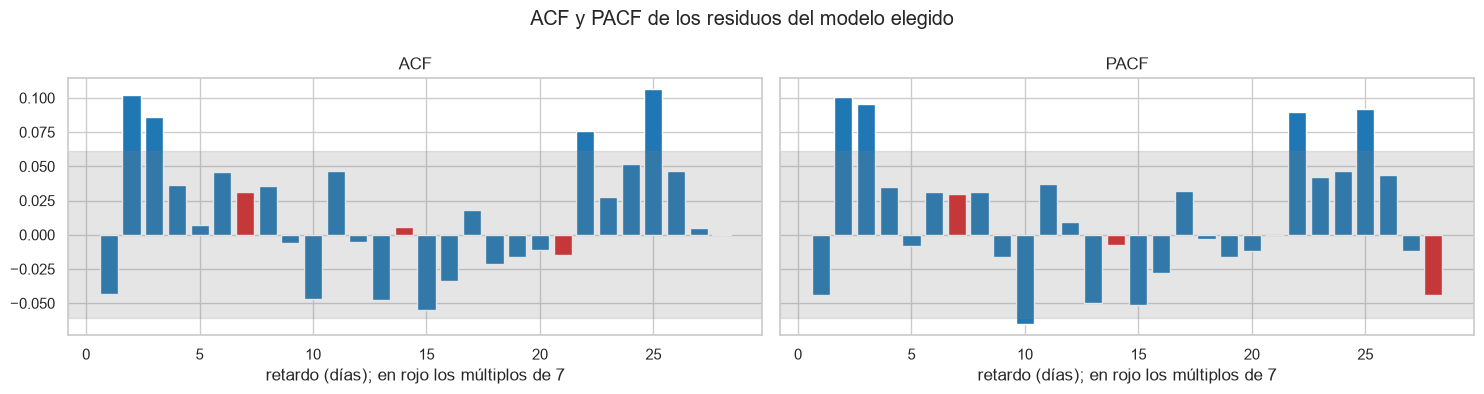

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0148      0.025      0.597      0.551      -0.034       0.063
sin_1         -4.9506      0.889     -5.571      0.000      -6.692      -3.209
cos_1         -6.8072      0.848     -8.026      0.000      -8.470      -5.145
ar.L1          0.3127      0.028     11.365      0.000       0.259       0.367
ar.S.L7        0.9997      0.000   2034.560      0.000       0.999       1.001
ma.S.L7       -0.9862      0.011    -87.202      0.000      -1.008      -0.964
sigma2       181.8324      6.829     26.628      0.000     168.448     195.216

Residuos: media 0.21, desvío 13.5

Franja de confianza: ±0.061. ACF de los residuos en los retardos que importan:
retardo    1    2     5     6     7     8     14    21   28
acf     -0.04  0.1  0.01  0.05  0.03  0.04  0.01 -0.02  0.0

Ljung-Box:
                  lb_stat  lb_pvalue
hasta

In [27]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Modelo elegido en la parte B (Q = 1, K = 1), ajustado con todo train
ESPECIFICACION = {"order": (1, 0, 0), "seasonal_order": (1, 0, 1, 7), "K": 1}
exog_train = terminos_fourier(y_modelo.index, K=ESPECIFICACION["K"])
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    modelo_final = SARIMAX(y_modelo, exog=exog_train, order=ESPECIFICACION["order"],
                           seasonal_order=ESPECIFICACION["seasonal_order"], trend="c").fit(disp=False, maxiter=200)
print(modelo_final.summary().tables[1])

# Residuos = lo que el modelo no logra explicar. Se descartan los primeros 14 días (arranque del cálculo).
residuos = modelo_final.resid.iloc[14:]
print(f"\nResiduos: media {residuos.mean():.2f}, desvío {residuos.std():.1f}")

tabla_res, banda_res = tabla_acf_pacf(residuos, nlags=28)
graficar_acf_pacf(tabla_res, banda_res, "ACF y PACF de los residuos del modelo elegido")
print(f"\nFranja de confianza: ±{banda_res:.3f}. ACF de los residuos en los retardos que importan:")
print(tabla_res.loc[[1, 2, 5, 6, 7, 8, 14, 21, 28], ["acf"]].round(2).T.to_string())

# Ljung-Box: ¿quedó autocorrelación en conjunto? (p alto = no se detecta nada). 3 = coeficientes AR/MA estimados
lb = acorr_ljungbox(residuos, lags=[7, 14, 28], model_df=3)
lb.index.name = "hasta el retardo"
print("\nLjung-Box:")
print(lb.round(3).to_string())

**Lectura:** los residuos tienen media 0,2 y desvío 13,5.
- **El ciclo semanal quedó bien captado:** los retardos 5 a 8, 14, 21 y 28 están dentro de la franja (±0,06).
- **Queda un poco de autocorrelación:** los retardos 2 y 3 valen 0,10 y 0,09, fuera de la franja, y Ljung-Box da `p` ≈ 0 en los tres cortes. Con 1.030 días el test detecta correlaciones chicas; igual, queda algo sin explicar.
- **El coeficiente estacional llegó al límite:** `ar.S.L7` = 0,9997 y `ma.S.L7` = −0,986. Se cancelan casi del todo, y el modelo funciona como uno con `D = 1`. Es lo que explica el empate entre `Q = 1` y `D = 1` de la parte B.

### 5.5 Una variante: `p = 2`

El retardo 2 de los residuos sugiere sumar un término AR. Se prueba **una sola variante** (`p = 2`), con una regla fijada antes de ver el resultado: se cambia el modelo solo si el MAE del backtesting baja **0,5 unidades/día o más**.

In [28]:
# Los residuos dejan el retardo 2 en 0,10 (fuera de la franja). Se prueba UNA variante, con una regla fijada antes de ver el resultado:
# se cambia el modelo solo si baja el MAE del backtesting en 0,5 unidades/día o más.
VARIANTE = {"order": (2, 0, 0), "seasonal_order": (1, 0, 1, 7), "K": 1}   # agrega p = 2
MEJORA_MINIMA = 0.5

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    ajuste_variante = SARIMAX(y_modelo, exog=exog_train, order=VARIANTE["order"],
                              seasonal_order=VARIANTE["seasonal_order"], trend="c").fit(disp=False, maxiter=200)
res_variante = ajuste_variante.resid.iloc[14:]
acf_variante, _ = tabla_acf_pacf(res_variante, nlags=28)
print("ACF de los residuos en los retardos 1, 2 y 3:")
print(pd.DataFrame({"elegido (p = 1)": tabla_res.loc[[1, 2, 3], "acf"], "variante (p = 2)": acf_variante.loc[[1, 2, 3], "acf"]}).round(2).T.to_string())
print(f"AIC: elegido {modelo_final.aic:.0f}, variante {ajuste_variante.aic:.0f}")

por_corte_variante = backtest(y_modelo, metodo_sarima(VARIANTE["order"], VARIANTE["seasonal_order"], K=VARIANTE["K"]))
mae_elegido = por_corte_k.loc["Q = 1 + Fourier K=1", "mae"].mean()
mae_variante = por_corte_variante["mae"].mean()
usar_variante = mae_variante <= mae_elegido - MEJORA_MINIMA
print(f"\nBacktesting (6 cortes): MAE elegido {mae_elegido:.1f}, variante {mae_variante:.1f} (hace falta una mejora de {MEJORA_MINIMA})")
print("Se usa:", "la variante p = 2" if usar_variante else "el modelo elegido en la parte B (p = 1)")

ACF de los residuos en los retardos 1, 2 y 3:
retardo              1     2     3
elegido (p = 1)  -0.04  0.10  0.09
variante (p = 2) -0.01  0.04 -0.07
AIC: elegido 8416, variante 8696

Backtesting (6 cortes): MAE elegido 11.7, variante 11.7 (hace falta una mejora de 0.5)
Se usa: el modelo elegido en la parte B (p = 1)


In [29]:
# ¿Por qué el AIC de la variante es peor? Un modelo con un coeficiente más no puede ajustar peor si el cálculo encuentra el óptimo.
comparacion_coef = pd.DataFrame({"elegido (p = 1)": modelo_final.params, "variante (p = 2)": ajuste_variante.params})
print(comparacion_coef.round(4).to_string(na_rep="-"))
print(f"\nLog-verosimilitud (más alto = mejor ajuste): elegido {modelo_final.llf:.0f}, variante {ajuste_variante.llf:.0f}")

           elegido (p = 1)  variante (p = 2)
ar.L1               0.3127            0.3686
ar.L2                    -           -0.0426
ar.S.L7             0.9997           -0.9974
cos_1              -6.8072           -7.0202
intercept           0.0148           99.2352
ma.S.L7            -0.9862            0.9998
sigma2            181.8324          238.7086
sin_1              -4.9506           -5.1799

Log-verosimilitud (más alto = mejor ajuste): elegido -4201, variante -4340


**Lectura:** el MAE no cambia (11,7 en los dos), así que por la regla se queda el modelo elegido. **Pero la prueba no sirve:** el AIC de la variante es peor (8.696 contra 8.416), y un modelo con un coeficiente más no puede ajustar peor si el cálculo encuentra el óptimo. La tabla lo muestra: el ajuste cayó en un resultado degenerado (`ar.S.L7` = −0,997, `ma.S.L7` = +1,000, constante 99 y log-verosimilitud mucho más baja). No se puede concluir que `p = 2` no sirva; solo que esta prueba no lo midió bien.

### 5.6 Medición única en `valid`

El modelo ya está decidido: **SARIMAX(1, 0, 0)(1, 0, 1)₇ con `K = 1`**. Se pronostican los 28 días de `valid` con el ajuste hecho solo con `train`, y se comparan con las dos líneas base. **Esta es la única vez que se mira `valid`**; lo que salga no se usa para retocar el modelo.

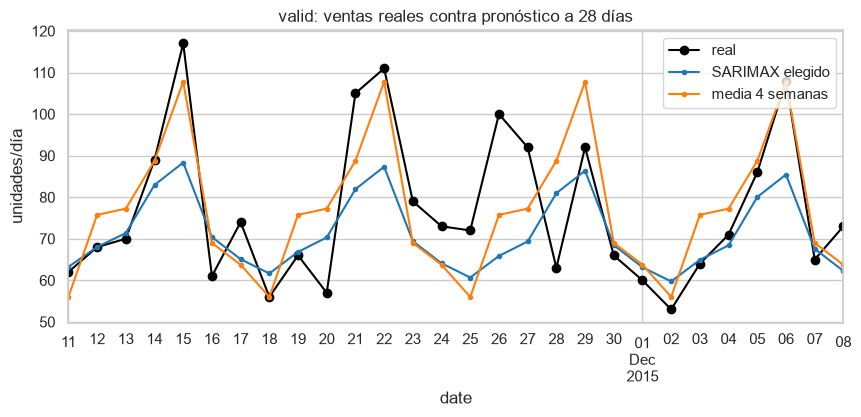

valid: 2015-11-11 -> 2015-12-08 (28 días), media 76.9
Modelo: order=(1, 0, 0), seasonal_order=(1, 0, 1, 7), K=1

                   mae  rmse  mae_%_de_la_media
SARIMAX elegido   10.4  13.9               13.5
media 4 semanas    9.2  11.4               12.0
naive estacional  10.1  14.4               13.1


In [30]:
# Medición única en valid (el modelo ya está decidido arriba)
FINAL = VARIANTE if usar_variante else ESPECIFICACION
RUTA_VALID = DATOS / "02_Validacion" / "validacion.parquet"
y_valid = extraer_serie(cargar_tablon(RUTA_VALID), SERIE)
assert y_valid.index[0] == y_modelo.index[-1] + pd.Timedelta(days=1), "valid debe empezar justo después de train"

pronosticos = {
    "SARIMAX elegido": metodo_sarima(FINAL["order"], FINAL["seasonal_order"], K=FINAL["K"])(y_modelo, len(y_valid)),
    "media 4 semanas": media_ultimas_semanas(y_modelo, len(y_valid)),
    "naive estacional": naive_estacional(y_modelo, len(y_valid)),
}
resultado_valid = pd.DataFrame({nombre: {"mae": mae(y_valid, p), "rmse": rmse(y_valid, p)} for nombre, p in pronosticos.items()}).T
resultado_valid["mae_%_de_la_media"] = 100 * resultado_valid["mae"] / y_valid.mean()
print(f"valid: {y_valid.index[0].date()} -> {y_valid.index[-1].date()} ({len(y_valid)} días), media {y_valid.mean():.1f}")
print(f"Modelo: order={FINAL['order']}, seasonal_order={FINAL['seasonal_order']}, K={FINAL['K']}\n")
print(resultado_valid.round(1).to_string())

fig, ax = plt.subplots(figsize=(10, 3.8))
y_valid.plot(ax=ax, color="black", marker="o", label="real")
for nombre, color in [("SARIMAX elegido", "tab:blue"), ("media 4 semanas", "tab:orange")]:
    ax.plot(y_valid.index, pronosticos[nombre], color=color, marker=".", label=nombre)
ax.set_title("valid: ventas reales contra pronóstico a 28 días"); ax.set_ylabel("unidades/día"); ax.legend()
plt.show()

> **Conclusión:** en `valid` el SARIMAX elegido **no le gana a la línea base**: MAE 10,4 contra 9,2 de la media de 4 semanas (y 10,1 del naive estacional). El backtesting decía lo contrario (11,7 contra 13,7). Todavía no hay un modelo que justifique su complejidad frente a la media de 4 semanas.

**Evidencia:**
- **Dos ventanas, dos resultados:** `valid` es una sola ventana de 28 días (11-nov a 8-dic), mientras que el backtesting tiene 6. Pesa más el backtesting, pero la diferencia es grande y no se puede explicar con certeza. Hipótesis **no verificadas**: los 6 cortes terminan el 10-nov y nunca cubren noviembre-diciembre, donde la ola anual de `K = 1` puede estar fallando; o `valid` es simplemente un mes atípico.
- **El modelo es frágil:** el coeficiente estacional quedó pegado a 1 y los residuos conservan algo de autocorrelación. La variante `p = 2` no se pudo evaluar por un ajuste degenerado.
- **No se retoca el modelo:** `valid` ya se usó. Cualquier cambio elegido mirando este resultado dejaría de ser una medición limpia.

**Qué hacemos:** dejar el resultado tal cual. Antes de cualquier mejora hay que decidir cómo evaluarla sin `valid` (por ejemplo, cortes de backtesting que cubran noviembre-diciembre) y revisar DEC-013 y DEC-014, porque el modelo terminó comportándose como uno con `D = 1`.

<a id="sec-5d"></a>

### 5.7 ¿Falla en noviembre-diciembre? Backtesting ampliado

`valid` salió peor que la línea base. Una hipótesis: los 6 cortes originales terminan el 10-nov y **nunca cubren noviembre-diciembre**, el período de `valid`, así que el modelo no se había probado ahí. Se prueba con las mismas 4 semanas del calendario que `valid` (11-nov a 8-dic) de **2013 y 2014**, que están dentro de `train`.

Dos avisos: (1) estas ventanas se eligieron **después** de ver `valid`, así que `valid` ya no es una medición del todo limpia; (2) la ventana de 2013 se ajusta con solo 314 días de historia, menos de un año.

In [31]:
# Backtesting ampliado: las mismas 4 semanas del calendario que valid (11-nov a 8-dic), pero de 2013 y de 2014 (están dentro de train)
FINES_NOV_DIC = ["2013-12-08", "2014-12-08"]


def backtest_fechas(y, fines, metodo, horizonte=HORIZONTE):
    """Como `backtest`, pero con la fecha de fin de cada prueba elegida a mano."""
    filas = []
    for fin in pd.to_datetime(fines):
        futuro = y.loc[fin - pd.Timedelta(days=horizonte - 1):fin]
        historia = y.loc[:futuro.index[0] - pd.Timedelta(days=1)]
        pronostico = metodo(historia, horizonte)
        filas.append({"desde": futuro.index[0].date(), "hasta": futuro.index[-1].date(),
                      "mae": mae(futuro, pronostico), "rmse": rmse(futuro, pronostico)})
    return pd.DataFrame(filas)


modelos_nov_dic = {
    "media 4 semanas": media_ultimas_semanas,
    "naive estacional": naive_estacional,
    "Q = 1 sin Fourier": metodo_sarima((1, 0, 0), (1, 0, 1, 7), K=0),
    "Q = 1 + Fourier K=1": metodo_sarima((1, 0, 0), (1, 0, 1, 7), K=1),
    "Q = 1 + Fourier K=2": metodo_sarima((1, 0, 0), (1, 0, 1, 7), K=2),
    "D = 1 sin Fourier": metodo_sarima((1, 0, 0), (0, 1, 1, 7), K=0),
    "D = 1 + Fourier K=1": metodo_sarima((1, 0, 0), (0, 1, 1, 7), K=1),
}
por_ventana = pd.concat({n: backtest_fechas(y_modelo, FINES_NOV_DIC, m) for n, m in modelos_nov_dic.items()}, names=["metodo", "corte"])

mae_nov_dic = por_ventana["mae"].unstack("corte")
mae_nov_dic.columns = ["nov-dic 2013", "nov-dic 2014"]
mae_nov_dic["promedio nov-dic"] = mae_nov_dic.mean(axis=1)
# Referencia: el MAE medio de los 6 cortes originales (parte B), que no cubren noviembre-diciembre
originales = {"media 4 semanas": por_corte.loc["media 4 semanas", "mae"], "naive estacional": por_corte.loc["naive estacional", "mae"],
              "Q = 1 sin Fourier": por_corte_sarima.loc["Q = 1", "mae"], "Q = 1 + Fourier K=1": por_corte_k.loc["Q = 1 + Fourier K=1", "mae"],
              "Q = 1 + Fourier K=2": por_corte_k.loc["Q = 1 + Fourier K=2", "mae"], "D = 1 sin Fourier": por_corte_sarima.loc["D = 1 (DEC-013)", "mae"],
              "D = 1 + Fourier K=1": por_corte_k.loc["D = 1 (DEC-013) + Fourier K=1", "mae"]}
mae_nov_dic["6 cortes originales"] = pd.Series({n: s.mean() for n, s in originales.items()})
print("MAE en noviembre-diciembre (unidades/día) y, al final, en los 6 cortes originales:")
print(mae_nov_dic.round(1).to_string())

MAE en noviembre-diciembre (unidades/día) y, al final, en los 6 cortes originales:
                     nov-dic 2013  nov-dic 2014  promedio nov-dic  6 cortes originales
metodo                                                                                
media 4 semanas              12.9          13.5              13.2                 13.7
naive estacional             16.4          15.0              15.7                 18.2
Q = 1 sin Fourier            11.1          13.9              12.5                 13.4
Q = 1 + Fourier K=1          11.3          13.3              12.3                 11.7
Q = 1 + Fourier K=2          11.6          12.9              12.3                 11.8
D = 1 sin Fourier            11.3          14.1              12.7                 13.3
D = 1 + Fourier K=1          11.3          13.3              12.3                 11.6


> **Conclusión:** la hipótesis se confirma **solo en parte**. En noviembre-diciembre de 2013 y 2014 el SARIMAX sigue ganándole a la media de 4 semanas, pero por poco: MAE 12,3 contra 13,2 (7 % menos, contra 15 % en los cortes originales), y en 2014 casi empata (13,3 contra 13,5). Junto con `valid` (10,4 contra 9,2), la ventaja del SARIMAX en este período es chica y no es consistente.

**Evidencia:**
- **Fourier no ayuda en estas semanas:** el MAE da 12,5 sin Fourier y 12,3 con `K = 1` o `K = 2`. En los cortes originales bajaba de 13,4 a 11,7. La ola anual aporta en el resto del año, no en noviembre-diciembre, pero tampoco empeora el resultado.
- **`Q = 1` y `D = 1` siguen empatados** (12,3 los dos con `K = 1`).
- **`valid` fue un mes fácil para la línea base:** todos los métodos erraron menos que en 2013 y 2014, pero la media de 4 semanas bajó de ~13 a 9,2 y el SARIMAX de ~12,3 a 10,4.
- **Son muy pocas ventanas:** dos, y una con poca historia. No alcanzan para separar un modelo flojo de un mes con mala suerte.

**Qué hacemos:** no cambiar el modelo con estas ventanas. El paso 5 se cierra con esta lectura: el SARIMAX gana en el backtesting (8 ventanas), pero pierde en `valid`, y **no se puede afirmar que supere a la línea base de forma consistente**. Los documentos (DEC-013, DEC-014 y el README) tienen que reflejarlo.